# TRABAJO FIN DE GRADO: Detección de TEA mediante sistemas de IA

#### **Estudiante**: Ángel Vilariño García
#### **Dirección**: Verónica Bolón Canedo y Brais Cancela Barizo

In [3]:
# Cargamos los resultados

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from IPython.display import display, HTML, display_html
import warnings
warnings.filterwarnings('ignore')
import pickle

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
import pyreadstat
import json
from pathlib import Path

# Cargamos los resultados completos
with open('resultados/resultados_completos_k.pkl', 'rb') as f:
    resultados_k = pickle.load(f)

# Cargamos los resultados sin nulos
with open('resultados/resultados_sin_nulos_k.pkl', 'rb') as f:
    resultados_sin_nulos_k = pickle.load(f)

# Cargamos los resultados sin nulos y sin pais
with open('resultados/resultados_sin_nulos_pais_k.pkl', 'rb') as f:
    resultados_sin_nulos_pais_k = pickle.load(f)

DIR_GRAFICAS = Path('graficas_cap5')
DIR_GRAFICAS.mkdir(exist_ok=True)

def guardar_grafica(nombre_archivo, fig=None, dpi=300):
    if fig is None:
        fig = plt.gcf()
    ruta = DIR_GRAFICAS / nombre_archivo
    fig.savefig(ruta, dpi=dpi, bbox_inches='tight')

In [4]:
# RESULTADOS PROMEDIO GLOBAL POR K, SELECTOR Y MODELO

df_global = []

for k, res in resultados_sin_nulos_pais_k.items():
    df_avg_k = res["resultados"].groupby(['FS','Modelo']).agg({
        'accuracy':'mean','precision':'mean','recall':'mean',
        'f1':'mean','roc_auc':'mean'
    }).reset_index()
    df_avg_k['k'] = k
    df_global.append(df_avg_k)

df_global = pd.concat(df_global, ignore_index=True)

with open('resultados/resultados_sin_pais_no_fs.pkl', 'rb') as f:
        df_no_fs_orig = pickle.load(f)
    
# Marcamos la estrategia como "NO FS"
df_no_fs_orig['FS'] = 'NO FS'
    
# Para que aparezca en todas las columnas de k en los pivots,
# replicamos el resultado para cada valor de k existente en df_global
ks_estudio = df_global['k'].unique()
lista_no_fs = []

for k in ks_estudio:
    temp = df_no_fs_orig.copy()
    temp['k'] = k
    lista_no_fs.append(temp)
        
df_no_fs_final = pd.concat(lista_no_fs, ignore_index=True)

# Combinamos con el df_global existente
df_global = pd.concat([df_global, df_no_fs_final], ignore_index=True)

## **1. Comparación con entrenamiento sin Columnas con más de 50% de valores faltantes**

### 1.1. Comparación de Mejores Combinaciones por K

In [5]:
# PROCESAMIENTO DE MEJORES COMBINACIONES
rows = []
for k in resultados_k:
    # Estrategia: Con Imputación
    res_imp = resultados_k[k]["resultados"].groupby(["FS", "Modelo"])["f1"].mean()
    best_imp_idx = res_imp.idxmax()
    best_imp_val = res_imp.max()
    
    # Estrategia: Sin Nulos
    res_sin = resultados_sin_nulos_k[k]["resultados"].groupby(["FS", "Modelo"])["f1"].mean()
    best_clean_idx = res_sin.idxmax()
    best_clean_val = res_sin.max()
    
    rows.append({
        "k": k,
        "Mejor Combinación (Imp)": f"{best_imp_idx[0]} + {best_imp_idx[1]}",
        "F1 Máx (Imp)": round(best_imp_val, 4),
        "Mejor Combinación (Sin)": f"{best_clean_idx[0]} + {best_clean_idx[1]}",
        "F1 Máx (Sin)": round(best_clean_val, 4),
        "Diferencia": round(best_imp_val - best_clean_val, 4)
    })

df_best_combo = pd.DataFrame(rows)

print("RESUMEN DE MEJORES CONFIGURACIONES POR CADA K")
display(df_best_combo)

RESUMEN DE MEJORES CONFIGURACIONES POR CADA K


,k,Mejor Combinación (Imp),F1 Máx (Imp),Mejor Combinación (Sin),F1 Máx (Sin),Diferencia
0,5,RFE-SVM + LR,0.7777,RFE-SVM + RF,0.7976,-0.0198
1,10,E2EFS + RF,0.8030,RFE-SVM + LR,0.8209,-0.0179
2,20,mRMR + MLP,0.8163,mRMR + LR,0.8078,0.0085
3,30,RFE-SVM + SVM,0.8189,mRMR + LR,0.8272,-0.0083
4,50,E2EFS + MLP,0.8309,RFE-SVM + GB,0.8359,-0.0050


### 1.2 Comparación de Rendimiento Promedio para cada K

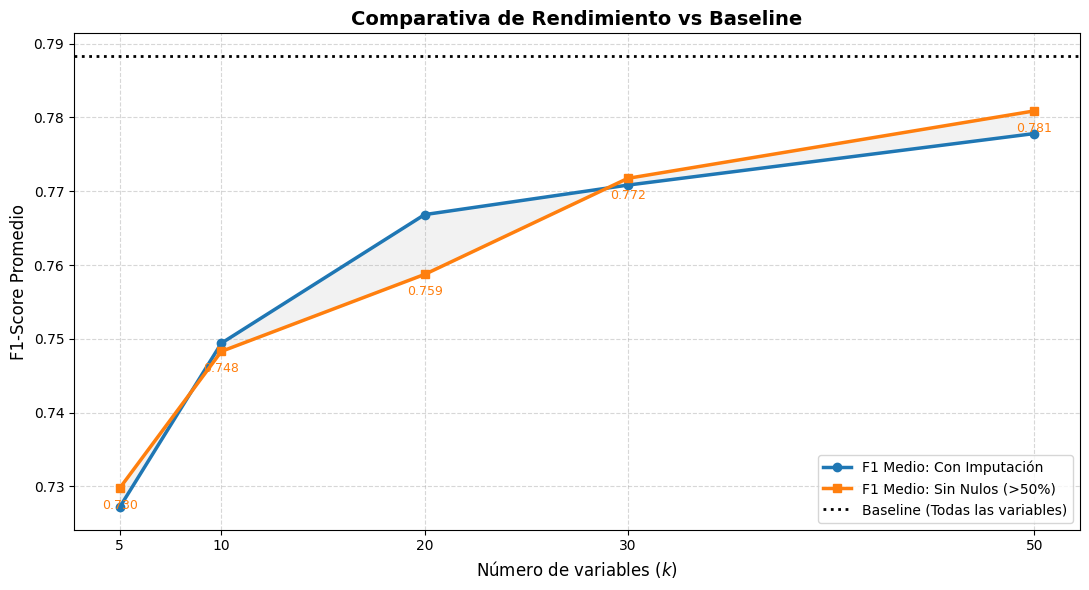

In [6]:
# 1. CÁLCULO DE MEDIAS GLOBALES POR K
ks = sorted(resultados_k.keys())
f1_medio_imp = [resultados_k[k]["resultados"]["f1"].mean() for k in ks]
f1_medio_sin = [resultados_sin_nulos_k[k]["resultados"]["f1"].mean() for k in ks]

# Calculamos el valor del baseline NO FS para la comparativa
# Este valor es constante (no depende de k)
f1_baseline = df_global[df_global['FS'] == 'NO FS']['f1'].mean()

# 2. CREACIÓN DEL GRÁFICO
plt.figure(figsize=(11, 6))

plt.plot(ks, f1_medio_imp, marker='o', lw=2.5, label='F1 Medio: Con Imputación', color='#1f77b4')
plt.plot(ks, f1_medio_sin, marker='s', lw=2.5, label='F1 Medio: Sin Nulos (>50%)', color='#ff7f0e')

# AÑADIMOS LA LÍNEA DE REFERENCIA "NO FS"
plt.axhline(y=f1_baseline, color='black', linestyle=':', lw=2, label='Baseline (Todas las variables)')

# Rellenar el área entre líneas
plt.fill_between(ks, f1_medio_imp, f1_medio_sin, color='gray', alpha=0.1)

# 3. ESTÉTICA Y ETIQUETAS
plt.title('Comparativa de Rendimiento vs Baseline', fontsize=14, fontweight='bold')
plt.xlabel('Número de variables ($k$)', fontsize=12)
plt.ylabel('F1-Score Promedio', fontsize=12)
plt.xticks(ks)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10, loc='lower right')

# Etiquetas de valor
for i, val in enumerate(f1_medio_sin):
    plt.annotate(f'{val:.3f}', (ks[i], f1_medio_sin[i]), textcoords="offset points", xytext=(0,-15), ha='center', fontsize=9, color='#ff7f0e')

plt.tight_layout()
guardar_grafica("comparativa_imputacion_eliminacion.png")
plt.show()

### 1.3 Comparación de Rendimiento Promedio por Selector y Modelo

In [7]:
# SELECTOR Y MODELO

# Función auxiliar para mostrar tablas lado a lado en el notebook
def display_side_by_side(dfs, captions):
    output = ""
    for df, cap in zip(dfs, captions):
        output += f'<div style="float: left; margin-right: 30px;"><b>{cap}</b><br>{df.to_html()}</div>'
    display(HTML(output))


print("\nCOMPARACIÓN AGREGADA (SELECTOR Y MODELO)")

# Procesar Selectores
comp_selector = []
for est, datos in [('Imp', resultados_k), ('Sin', resultados_sin_nulos_k)]:
    for k, data in datos.items():
        df_fs = data["resultados"].groupby('FS')['f1'].mean().reset_index()
        df_fs['Estrategia'] = est
        comp_selector.append(df_fs)

pivot_sel = pd.concat(comp_selector).pivot_table(index='FS', columns='Estrategia', values='f1', aggfunc='mean')
pivot_sel['Diff'] = (pivot_sel['Imp'] - pivot_sel['Sin']).round(4)

# Procesar Modelos
comp_modelo = []
for est, datos in [('Imp', resultados_k), ('Sin', resultados_sin_nulos_k)]:
    for k, data in datos.items():
        df_mod = data["resultados"].groupby('Modelo')['f1'].mean().reset_index()
        df_mod['Estrategia'] = est
        comp_modelo.append(df_mod)

pivot_mod = pd.concat(comp_modelo).pivot_table(index='Modelo', columns='Estrategia', values='f1', aggfunc='mean')
pivot_mod['Diff'] = (pivot_mod['Imp'] - pivot_mod['Sin']).round(4)

display_side_by_side([pivot_sel, pivot_mod], ["Rendimiento por Selector", "Rendimiento por Modelo"])


COMPARACIÓN AGREGADA (SELECTOR Y MODELO)


Estrategia,Imp,Sin,Diff
FS,,,
ANOVA,0.753951,0.756046,-0.0021
E2EFS,0.776212,0.769630,0.0066
MI,0.729681,0.730287,-0.0006
RFE-SVM,0.783193,0.781334,0.0019
ReliefF,0.749477,0.748175,0.0013
mRMR,0.757992,0.761857,-0.0039
Estrategia,Imp,Sin,Diff
Modelo,,,
GB,0.765702,0.763357,0.0023


### 1.4 Comparación de Top 20 Variables más Consistentes

In [8]:
# ANÁLISIS DE CONSENSO (TOP 20 LADO A LADO)
print("\nCOMPARACIÓN DE VARIABLES TOP 20 (k=20)")

k_analisis = 20

def calcular_consenso(stability_df):
    df_k = stability_df[stability_df['selector'].notna()].copy()
    df_cons = df_k.groupby('feature_name').agg({'selector': 'nunique', 'pct_selected': 'mean'})
    num_sel = df_k['selector'].nunique()
    df_cons['Score'] = ((df_cons['selector'] / num_sel) * 50 + (df_cons['pct_selected'] / 100) * 50).round(2)
    return df_cons.sort_values('Score', ascending=False)

cons_imp = calcular_consenso(resultados_k[k_analisis]["stability"]).head(20)
cons_sin = calcular_consenso(resultados_sin_nulos_k[k_analisis]["stability"]).head(20)

display_side_by_side([cons_imp[['Score']], cons_sin[['Score']]], ["Top 20 (Con Imputación)", "Top 20 (Sin Nulos)"])

# Diferencias
set_imp = set(cons_imp.index)
set_sin = set(cons_sin.index)

print(f"\nANÁLISIS DE VARIABLES:")
print(f"• Comunes: {len(set_imp & set_sin)}/20")
print(f"• Solo en Imputación (se perdieron al filtrar nulos): {sorted(list(set_imp - set_sin))}")
print(f"• Solo en Sin Nulos (ganaron peso al filtrar): {sorted(list(set_sin - set_imp))}")


COMPARACIÓN DE VARIABLES TOP 20 (k=20)


,Score
feature_name,
permanece_apartado,95.00
Pais,93.33
cuenta_historia,93.33
intercambia_objetos,90.00
evita_contacto_ocular,86.67
repite_sonidos_ininteligibles,83.33
responde_negativamente_a_ordenes,78.33
hacer_cosas_repetidamente,73.67
trabaja_ritmo_regular,73.33



ANÁLISIS DE VARIABLES:
• Comunes: 18/20
• Solo en Imputación (se perdieron al filtrar nulos): ['comunicq', 'serv_act2']
• Solo en Sin Nulos (ganaron peso al filtrar): ['esperar_turno', 'intsocq']


## **2. Comparación con entrenamiento sin Columnas con más de 50% de valores faltantes y eliminando la variable País**

### 2.1. Comparación de F1 Medio por K

In [9]:
# COMPARATIVA DE F1 MEDIO GLOBAL POR K

rows = []
for k in resultados_sin_nulos_k.keys():
    # Calculamos la media de TODAS las combinaciones para ese k
    f1_nulos_medio = resultados_sin_nulos_k[k]["resultados"]["f1"].mean()
    f1_pais_medio = resultados_sin_nulos_pais_k[k]["resultados"]["f1"].mean()
    
    rows.append({
        "k": k,
        "F1 Medio (Solo Nulos)": round(f1_nulos_medio, 4),
        "F1 Medio (Sin Pais)": round(f1_pais_medio, 4),
        "Diferencia (Impacto)": round(f1_pais_medio - f1_nulos_medio, 4)
    })

print("COMPARATIVA DE ROBUSTEZ: F1 MEDIO GLOBAL POR K")
df_impacto_medio = pd.DataFrame(rows)
display(df_impacto_medio)

COMPARATIVA DE ROBUSTEZ: F1 MEDIO GLOBAL POR K


,k,F1 Medio (Solo Nulos),F1 Medio (Sin Pais),Diferencia (Impacto)
0,5,0.7298,0.7221,-0.0076
1,10,0.7483,0.7485,0.0002
2,20,0.7587,0.7623,0.0036
3,30,0.7718,0.7731,0.0013
4,50,0.7809,0.7733,-0.0076


In [10]:
# Mostrar el F1 y accuracy máximo por k
print("COMPARATIVA DE MEJORES CONFIGURACIONES POR K AGREGANDO POR SELECTOR Y MODELO")
rows_best = []
for k in resultados_sin_nulos_k.keys():
    # Mejor con nulos
    res_nulos_fs = resultados_sin_nulos_k[k]["resultados"].groupby(["FS", "Modelo"])["f1"].mean()
    best_nulos_idx = res_nulos_fs.idxmax()
    best_nulos_val = res_nulos_fs.max()
    
    # Mejor sin país
    res_pais_fs = resultados_sin_nulos_pais_k[k]["resultados"].groupby(["FS", "Modelo"])["f1"].mean()
    best_pais_idx = res_pais_fs.idxmax()
    best_pais_val = res_pais_fs.max()

    # Mejor accuracy con nulos
    res_nulos_acc = resultados_sin_nulos_k[k]["resultados"].groupby(["FS", "Modelo"])["accuracy"].mean()
    best_nulos_acc_idx = res_nulos_acc.idxmax()
    best_nulos_acc_val = res_nulos_acc.max()
    # Mejor accuracy sin país
    res_pais_acc = resultados_sin_nulos_pais_k[k]["resultados"].groupby(["FS", "Modelo"])["accuracy"].mean()
    best_pais_acc_idx = res_pais_acc.idxmax()
    best_pais_acc_val = res_pais_acc.max()
    
    rows_best.append({
        "k": k,
        "Mejor Config (Solo Nulos)": f"{best_nulos_idx[0]} + {best_nulos_idx[1]}",
        "F1 Máx (Solo Nulos)": round(best_nulos_val, 4),
        "Mejor Config (Sin Pais)": f"{best_pais_idx[0]} + {best_pais_idx[1]}",
        "F1 Máx (Sin Pais)": round(best_pais_val, 4),
        "Diferencia (Impacto)": round(best_pais_val - best_nulos_val, 4),
        "Acc Máx (Solo Nulos)": round(best_nulos_acc_val, 4),
        "Acc Máx (Sin Pais)": round(best_pais_acc_val, 4),
        "Diferencia Acc": round(best_pais_acc_val - best_nulos_acc_val, 4)
    })

df_impacto_best = pd.DataFrame(rows_best)
display(df_impacto_best)

COMPARATIVA DE MEJORES CONFIGURACIONES POR K AGREGANDO POR SELECTOR Y MODELO


,k,Mejor Config (Solo Nulos),F1 Máx (Solo Nulos),Mejor Config (Sin Pais),F1 Máx (Sin Pais),Diferencia (Impacto),Acc Máx (Solo Nulos),Acc Máx (Sin Pais),Diferencia Acc
0,5,RFE-SVM + RF,0.7976,E2EFS + LR,0.7782,-0.0193,0.7993,0.7799,-0.0194
1,10,RFE-SVM + LR,0.8209,mRMR + LR,0.8023,-0.0186,0.8225,0.8037,-0.0188
2,20,mRMR + LR,0.8078,mRMR + GB,0.8077,-0.0001,0.8087,0.8086,-0.0001
3,30,mRMR + LR,0.8272,ANOVA + GB,0.8175,-0.0096,0.8279,0.8182,-0.0096
4,50,RFE-SVM + GB,0.8359,ANOVA + GB,0.8175,-0.0184,0.8373,0.8181,-0.0192


In [11]:
# RANKING ABSOLUTO: TOP 10 MEJORES CONFIGURACIONES (ESTRATEGIA FINAL)

# Recopilamos todos los resultados individuales de cada K en un solo DataFrame
lista_ranking = []
for k in sorted(resultados_sin_nulos_pais_k.keys()):
    df_k = resultados_sin_nulos_pais_k[k]["resultados"].copy()
    df_k['k'] = k  # Añadimos la columna k para saber de dónde viene
    lista_ranking.append(df_k)

df_ranking_final = pd.concat(lista_ranking, ignore_index=True)

# Reordenamos las columnas para que sea fácil de leer
columnas_orden = ['k', 'FS', 'Modelo', 'f1', 'accuracy', 'precision', 'recall', 'roc_auc']
df_ranking_final = df_ranking_final[columnas_orden]

# Ordenamos por F1-Score (el mejor balance entre precisión y recall)
top_10_absoluto = df_ranking_final.sort_values(by='f1', ascending=False).head(10)

print(" TOP 10 CONFIGURACIONES ÓPTIMAS (Sin Nulos y Sin País)")
display(top_10_absoluto.style.background_gradient(cmap='Greens', subset=['f1', 'accuracy', 'roc_auc']))

 TOP 10 CONFIGURACIONES ÓPTIMAS (Sin Nulos y Sin País)


,k,FS,Modelo,f1,accuracy,precision,recall,roc_auc
600,30,RFE-SVM,SVM,0.904762,0.904762,0.904762,0.904762,0.965909
415,20,mRMR,MLP,0.904762,0.904762,0.908874,0.904762,0.943182
779,50,mRMR,LR,0.904762,0.904762,0.908874,0.904762,0.979545
683,30,E2EFS,LR,0.881156,0.880952,0.882359,0.880952,0.908467
677,30,RFE-SVM,LR,0.881156,0.880952,0.882359,0.880952,0.869565
679,30,E2EFS,MLP,0.881155,0.880952,0.890368,0.880952,0.899314
420,20,RFE-SVM,SVM,0.881020,0.880952,0.882086,0.880952,0.945455
599,30,mRMR,LR,0.881020,0.880952,0.882086,0.880952,0.970455
759,50,MI,RF,0.881020,0.880952,0.882086,0.880952,0.940909
604,30,RFE-SVM,GB,0.881020,0.880952,0.882086,0.880952,0.947727


In [12]:
# ANÁLISIS DEL MODELO GANADOR (#1)

# Tomamos los datos del mejor modelo del ranking
mejor_config = top_10_absoluto.iloc[0]
k_top = mejor_config['k']
fs_top = mejor_config['FS']
mod_top = mejor_config['Modelo']

print(f" ANÁLISIS DEL GANADOR: {mod_top} con selector {fs_top} (k={k_top})")

# 1. Recuperamos las variables que eligió este selector específico para este k
# Nota: Accedemos a la lista de variables del objeto de estabilidad
stab_top = resultados_sin_nulos_pais_k[k_top]["stability"]
vars_ganadoras = stab_top[stab_top['selector'] == fs_top]['feature_name'].unique().tolist()

print(f"\n Las {k_top} variables que utiliza el mejor modelo son:")
# Mostrar 30 variables con mayor estabilidad
stab_vars = stab_top[stab_top['selector'] == fs_top].set_index('feature_name').loc[vars_ganadoras]
stab_vars_sorted = stab_vars.sort_values(by='pct_selected', ascending=False)
display(stab_vars_sorted.head(30).style.background_gradient(cmap='Greens', subset=['pct_selected']))

 ANÁLISIS DEL GANADOR: SVM con selector RFE-SVM (k=30)

 Las 30 variables que utiliza el mejor modelo son:


,selector,feature_idx,count,pct_selected
feature_name,,,,
cuenta_historia,RFE-SVM,49,5,100.000000
esperar_turno,RFE-SVM,45,5,100.000000
Hace_rayas_papel,RFE-SVM,24,5,100.000000
Medicamentos,RFE-SVM,14,5,100.000000
intercambia_objetos,RFE-SVM,80,5,100.000000
evita_contacto_ocular,RFE-SVM,127,5,100.000000
repite_sonidos_ininteligibles,RFE-SVM,152,5,100.000000
responde_negativamente_a_ordenes,RFE-SVM,167,5,100.000000
sobla_carta_tres,RFE-SVM,32,4,80.000000


### 2.2. Gráficas comparativas de Rendimiento por Selector y Modelo

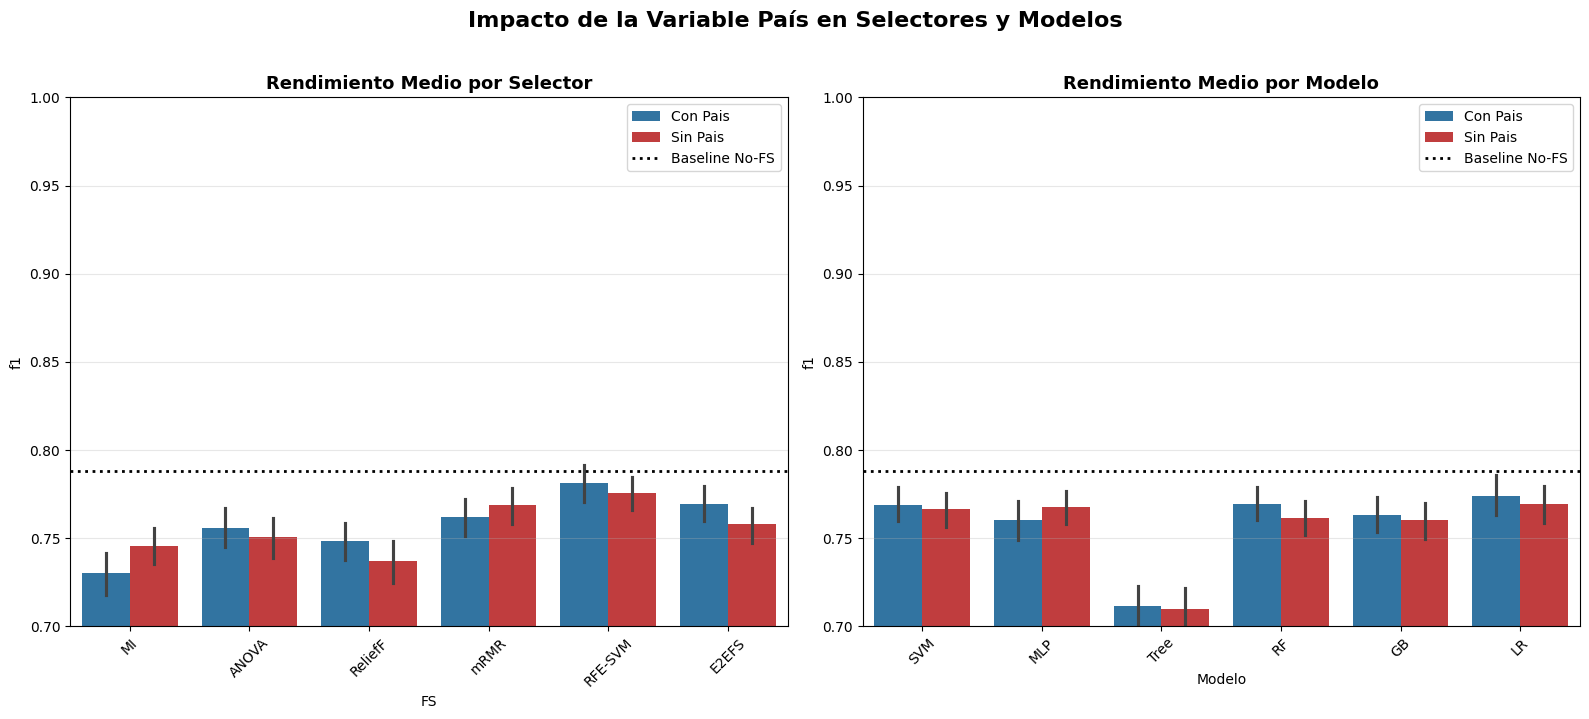

In [13]:
# 1. Preparación de datos
ks = sorted(resultados_sin_nulos_k.keys())
data_list = []
for est, d_res in [('Con Pais', resultados_sin_nulos_k), ('Sin Pais', resultados_sin_nulos_pais_k)]:
    for k in ks:
        temp = d_res[k]["resultados"].copy()
        temp['k'] = k
        temp['Estrategia'] = est
        data_list.append(temp)
df_total = pd.concat(data_list)

# Recuperamos el valor del baseline ético (Sin Pais, Sin FS)
f1_baseline_etico = df_global[df_global['FS'] == 'NO FS']['f1'].mean()

# 2. Creación del Panel de Barras
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Subplot A: Rendimiento por Selector
sns.barplot(data=df_total, x='FS', y='f1', hue='Estrategia', ax=axes[0], palette=['#1f77b4', '#d62728'])
axes[0].axhline(y=f1_baseline_etico, color='black', linestyle=':', lw=2, label='Baseline No-FS')
axes[0].set_title('Rendimiento Medio por Selector', fontweight='bold', fontsize=13)
axes[0].set_ylim(0.7, 1.0)
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.3)
axes[0].legend()

# Subplot B: Rendimiento por Modelo
sns.barplot(data=df_total, x='Modelo', y='f1', hue='Estrategia', ax=axes[1], palette=['#1f77b4', '#d62728'])
axes[1].axhline(y=f1_baseline_etico, color='black', linestyle=':', lw=2, label='Baseline No-FS')
axes[1].set_title('Rendimiento Medio por Modelo', fontweight='bold', fontsize=13)
axes[1].set_ylim(0.7, 1.0)
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', alpha=0.3)
axes[1].legend()

plt.suptitle('Impacto de la Variable País en Selectores y Modelos', 
             fontsize=16, fontweight='bold', y=1.02)

plt.tight_layout()
guardar_grafica("comparativa_selector_modelo_pais.png")
plt.show()

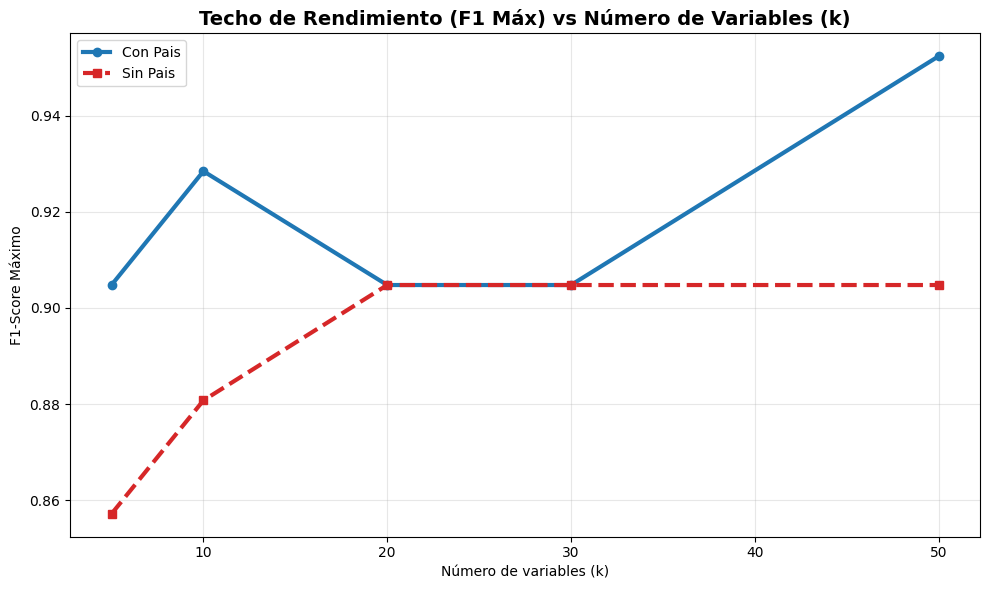

In [14]:
# 1. Preparación de datos para la curva
ks = sorted(resultados_sin_nulos_k.keys())
f1_max_nulos = [resultados_sin_nulos_k[k]["resultados"]["f1"].max() for k in ks]
# Corregido: resultados_sin_nulos_pais_k
f1_max_pais = [resultados_sin_nulos_pais_k[k]["resultados"]["f1"].max() for k in ks]

# 2. Creación de la gráfica
plt.figure(figsize=(10, 6))
plt.plot(ks, f1_max_nulos, 'o-', label='Con Pais', color='#1f77b4', lw=3)
plt.plot(ks, f1_max_pais, 's--', label='Sin Pais', color='#d62728', lw=3)

plt.title('Techo de Rendimiento (F1 Máx) vs Número de Variables (k)', fontweight='bold', fontsize=14)
plt.xlabel('Número de variables (k)')
plt.ylabel('F1-Score Máximo')
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
guardar_grafica("comparativa_f1_k_pais.png")
plt.show()

### 2.3. Comparación de Top 20 Variables más Consistentes

In [15]:
# ANÁLISIS DE CONSENSO: IMPACTO DE LA ELIMINACIÓN DE 'PAIS' (k=20)

print("COMPARATIVA DE TOP 20 VARIABLES (k=20)")

# Calculamos el consenso para ambos experimentos usando tus variables exactas
# Accedemos a [k_analisis]["stability"] para pasarle el DataFrame correcto a la función
top_con_pais = calcular_consenso(resultados_sin_nulos_k[k_analisis]["stability"]).head(20)
top_sin_pais = calcular_consenso(resultados_sin_nulos_pais_k[k_analisis]["stability"]).head(20)

# Visualización lado a lado
display_side_by_side(
    [top_con_pais[['Score']], top_sin_pais[['Score']]], 
    ["Top 20 (Con variable Pais)", "Top 20 (Sin variable Pais)"]
)

# Análisis de diferencias y nuevas incorporaciones
set_con_pais = set(top_con_pais.index)
set_sin_pais = set(top_sin_pais.index)
comunes = set_con_pais & set_sin_pais
nuevas_incorporaciones = set_sin_pais - set_con_pais
desaparecidas = set_con_pais - set_sin_pais

print(f"\nANÁLISIS DE CAMBIOS TRAS ELIMINAR 'PAIS':")
print(f"• Variables que se mantienen (Robustas): {len(comunes)}/20")
print(f"• Variables que salen del Top 20: {sorted(list(desaparecidas))}")
print(f"\n Variables que ganaron importancia clínica al eliminar el sesgo geográfico:")
for i, feat in enumerate(sorted(list(nuevas_incorporaciones)), 1):
    print(f"  {i}. {feat}")

COMPARATIVA DE TOP 20 VARIABLES (k=20)


,Score
feature_name,
cuenta_historia,93.33
Pais,91.67
intercambia_objetos,91.67
permanece_apartado,90.00
evita_contacto_ocular,86.67
repite_sonidos_ininteligibles,81.67
responde_negativamente_a_ordenes,80.83
hacer_cosas_repetidamente,76.67
trabaja_ritmo_regular,73.33



ANÁLISIS DE CAMBIOS TRAS ELIMINAR 'PAIS':
• Variables que se mantienen (Robustas): 18/20
• Variables que salen del Top 20: ['Pais', 'intsocq']

 Variables que ganaron importancia clínica al eliminar el sesgo geográfico:
  1. barrio_curza_calles
  2. fecuencia_estereotipias


In [16]:
# Extraer la lista de nombres de las variables del índice del DataFrame
# Usamos 'top_sin_pais' que es el modelo objetivo
mejores_variables_list = top_sin_pais.index.tolist()

# Guardar en un archivo JSON
with open('resultados/mejores_variables.json', 'w', encoding='utf-8') as f:
    json.dump(mejores_variables_list, f, ensure_ascii=False, indent=4)

print(f" Se han guardado las {len(mejores_variables_list)} variables en 'resultados/mejores_variables.json'")
print("Variables guardadas:", mejores_variables_list)

 Se han guardado las 20 variables en 'resultados/mejores_variables.json'
Variables guardadas: ['permanece_apartado', 'intercambia_objetos', 'cuenta_historia', 'evita_contacto_ocular', 'repite_sonidos_ininteligibles', 'responde_negativamente_a_ordenes', 'Medicamentos', 'Frecuencia_retraimiento', 'hacer_cosas_repetidamente', 'trabaja_ritmo_regular', 'Gravedad_retraimiento', 'Localiza_informacion', 'Gravedad_no_colaboradora', 'no_inicia_conversaciones', 'fecuencia_estereotipias', 'ofrece_ayuda', 'barrio_curza_calles', 'Retraimiento_atencion', 'mira_lejos_cuando_se_lo_mira', 'esperar_turno']


## **3. Análisis de rendimiento por selector, modelo y número de características SIN NULOS NI PAÍS**

### 3.1. Análisis selector × k

In [17]:
# RENDIMIENTO PROMEDIO POR SELECTOR EN FUNCIÓN DE K

pivot_fs = df_global.pivot_table(index="FS", columns="k", values="f1", aggfunc="mean").round(4)

print("RENDIMIENTO PROMEDIO de F1 POR SELECTOR EN FUNCIÓN DE K:")
display(pivot_fs.style.background_gradient(cmap="Blues"))

RENDIMIENTO PROMEDIO de F1 POR SELECTOR EN FUNCIÓN DE K:


k,5,10,20,30,50
FS,,,,,
ANOVA,0.704300,0.736600,0.756600,0.778300,0.777500
E2EFS,0.746100,0.748300,0.754200,0.767600,0.773300
MI,0.714300,0.726100,0.761100,0.760400,0.764500
NO FS,0.788300,0.788300,0.788300,0.788300,0.788300
RFE-SVM,0.747200,0.775200,0.782000,0.790100,0.783200
ReliefF,0.695400,0.738200,0.734700,0.754300,0.762900
mRMR,0.725400,0.766400,0.785600,0.787900,0.778500


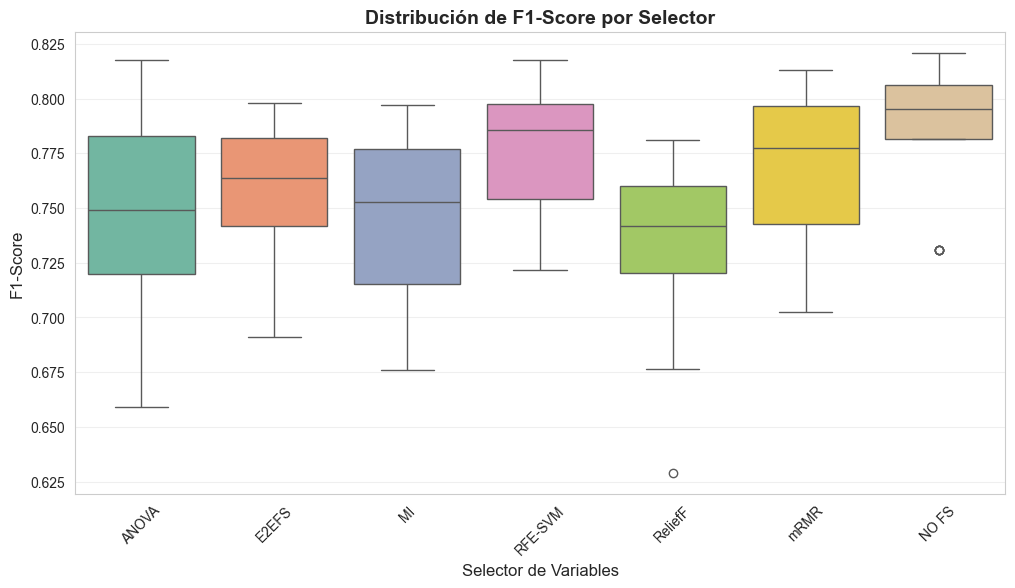

In [39]:
# Boxplot de F1 por selector

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_global, x='FS', y='f1', palette='Set2')
plt.title('Distribución de F1-Score por Selector', fontweight='bold', fontsize=14)
plt.xlabel('Selector de Variables', fontsize=12)
plt.ylabel('F1-Score', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
guardar_grafica("boxplot_f1_por_selector.png")
plt.show()

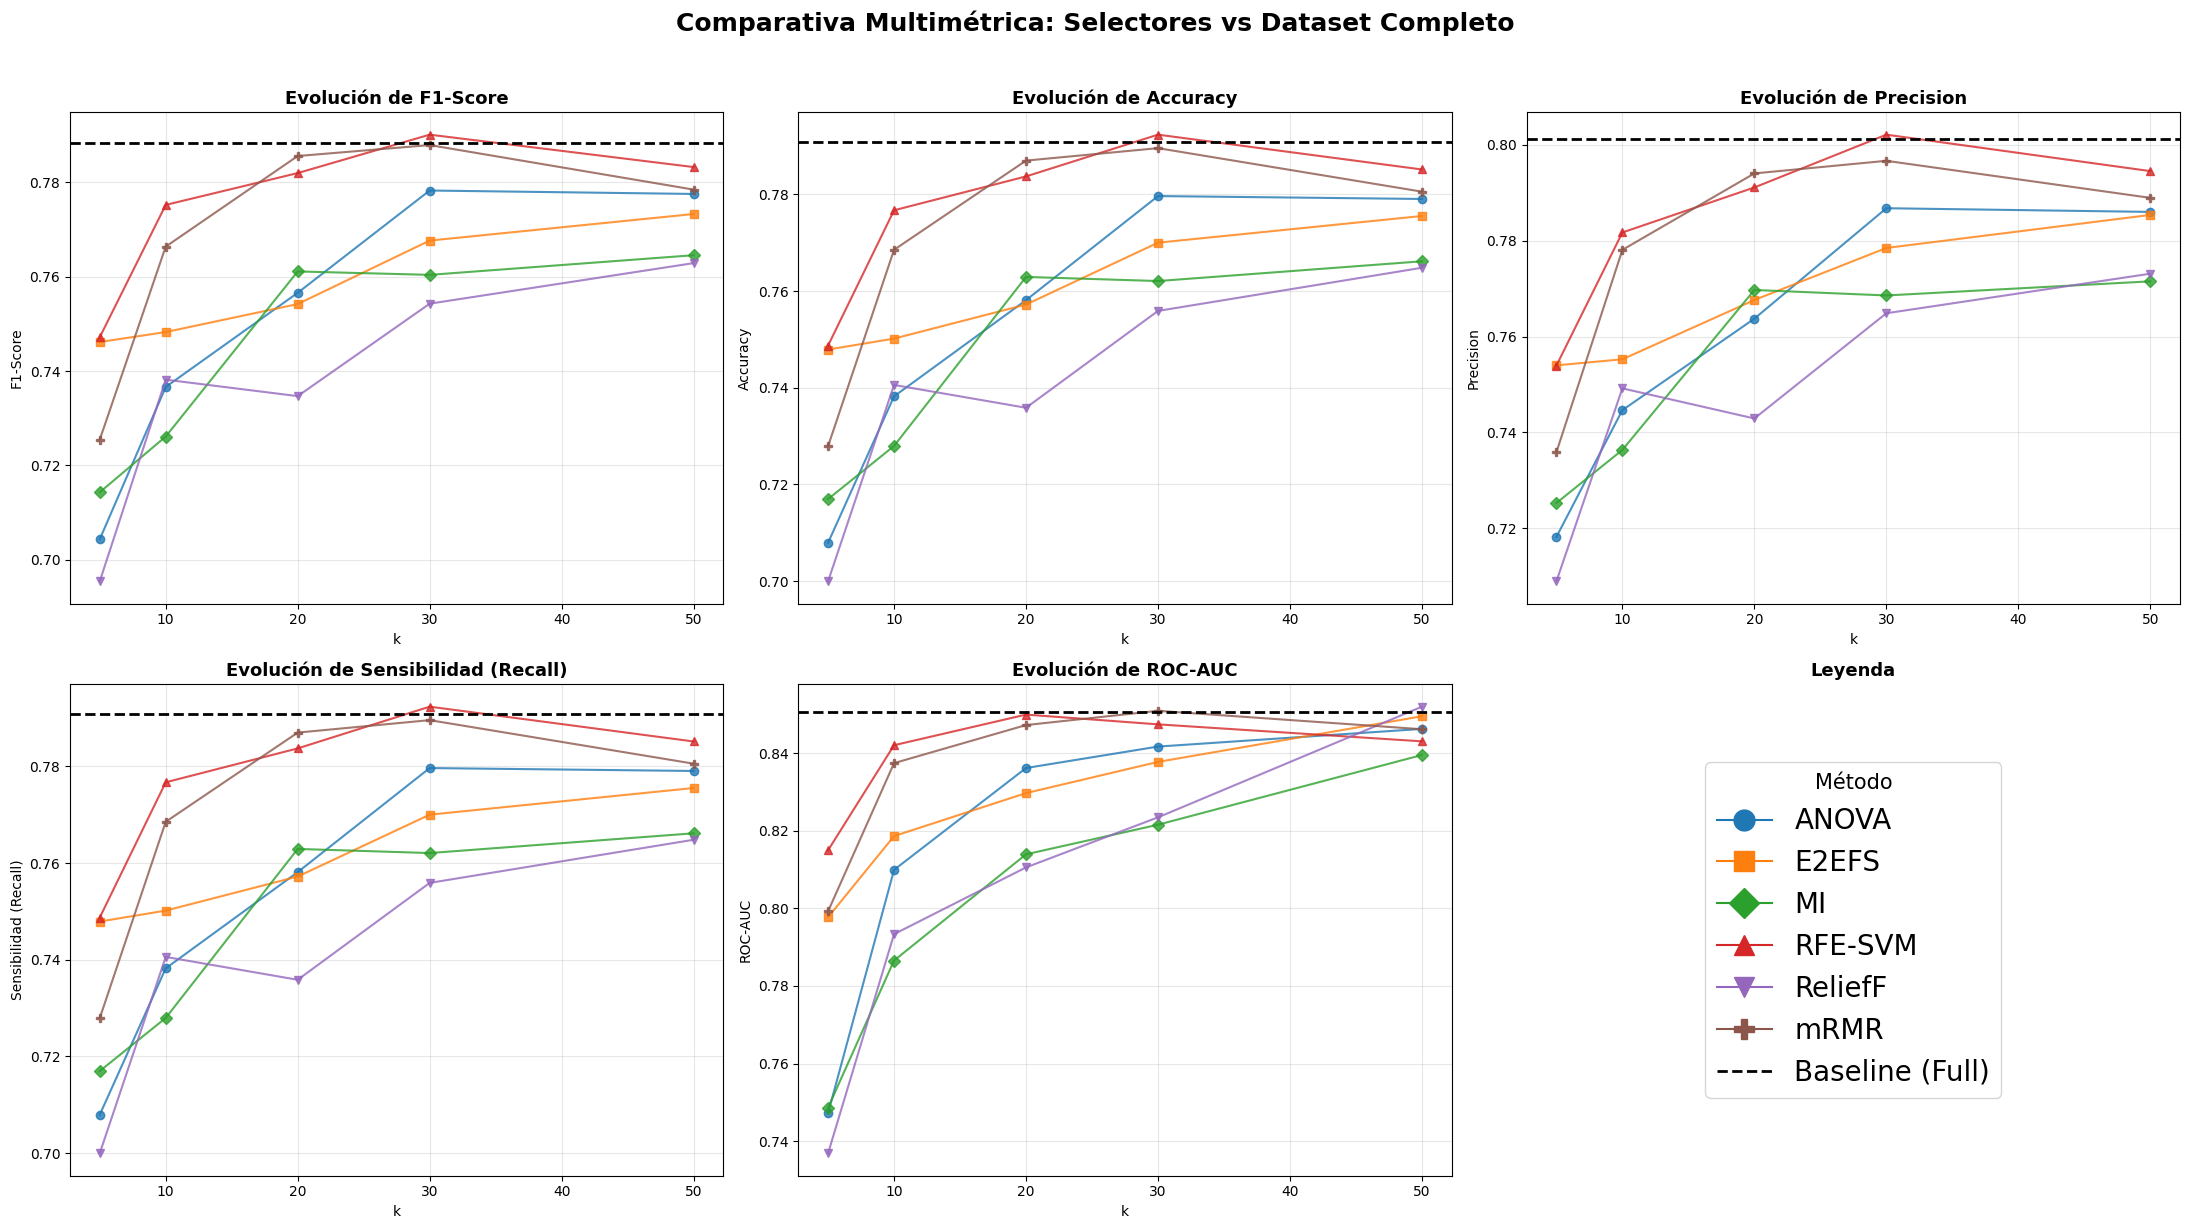

In [ ]:
# SUBPLOT: EVOLUCIÓN DE TODAS LAS MÉTRICAS VS BASELINE

markers = ['o', 's', 'D', '^', 'v', 'P', '*', 'X', 'h', '8']

metricas_lista = ['f1', 'accuracy', 'precision', 'recall', 'roc_auc']
titulos_met = ['F1-Score', 'Accuracy', 'Precision', 'Sensibilidad (Recall)', 'ROC-AUC']

fig, axes = plt.subplots(2, 3, figsize=(22, 12))
axes = axes.flatten()

selectores_reales = sorted([s for s in df_global['FS'].unique() if s != 'NO FS'])
palette = sns.color_palette("tab10", n_colors=len(selectores_reales))

for i, met in enumerate(metricas_lista):
    ax = axes[i]
    df_plot = df_global[df_global['FS'].isin(selectores_reales)].groupby(['k', 'FS'])[met].mean().unstack()

    for j, col in enumerate(df_plot.columns):
        ax.plot(
            df_plot.index,
            df_plot[col],
            marker=markers[j % len(markers)],
            color=palette[j % len(palette)],
            label=col,
            lw=1.5,
            alpha=0.8
        )

    if 'NO FS' in df_global['FS'].values:
        baseline_val = df_global[df_global['FS'] == 'NO FS'][met].mean()
        ax.axhline(y=baseline_val, color='black', linestyle='--', lw=2, label='Baseline (Full)')

    ax.set_title(f"Evolución de {titulos_met[i]}", fontsize=13, fontweight='bold')
    ax.set_xlabel("k")
    ax.set_ylabel(titulos_met[i])
    ax.grid(True, alpha=0.3)

# Usamos el último subplot para la leyenda
ax_leg = axes[-1]
ax_leg.axis('off')

legend_handles = [
    Line2D([0], [0],
           color=palette[j % len(palette)],
           marker=markers[j % len(markers)],
           label=sel,
           lw=1.5,
           markersize=15)
    for j, sel in enumerate(selectores_reales)
]
legend_handles.append(Line2D([0], [0], color='black', linestyle='--', lw=2, label='Baseline (Full)'))

ax_leg.legend(handles=legend_handles, loc='center', title='Método', fontsize=20, title_fontsize=15)
ax_leg.set_title("Leyenda", fontsize=13, fontweight='bold')

plt.suptitle(
    "Comparativa Multimétrica: Selectores vs Dataset Completo",
    fontsize=18,
    fontweight='bold',
    y=1.02
)
plt.tight_layout()
guardar_grafica("evolucion_metricas_vs_k.png")
plt.show()

### 3.2 Análisis por modelo × k 

In [18]:
# RENDIMIENTO PROMEDIO POR MODELO EN FUNCIÓN DE K

pivot_modelo = df_global.pivot_table(index="Modelo", columns="k", values="f1", aggfunc="mean").round(4)

print("RENDIMIENTO PROMEDIO de F1 POR MODELO EN FUNCIÓN DE K:")
display(pivot_modelo.style.background_gradient(cmap="Blues"))

RENDIMIENTO PROMEDIO de F1 POR MODELO EN FUNCIÓN DE K:


k,5,10,20,30,50
Modelo,,,,,
GB,0.735600,0.750800,0.777600,0.788500,0.792200
LR,0.747200,0.763800,0.775300,0.787900,0.782000
MLP,0.737100,0.762600,0.780800,0.791500,0.786600
RF,0.729800,0.761100,0.773000,0.787400,0.788900
SVM,0.744900,0.764600,0.773900,0.783700,0.784200
Tree,0.694900,0.722000,0.715800,0.712700,0.718900


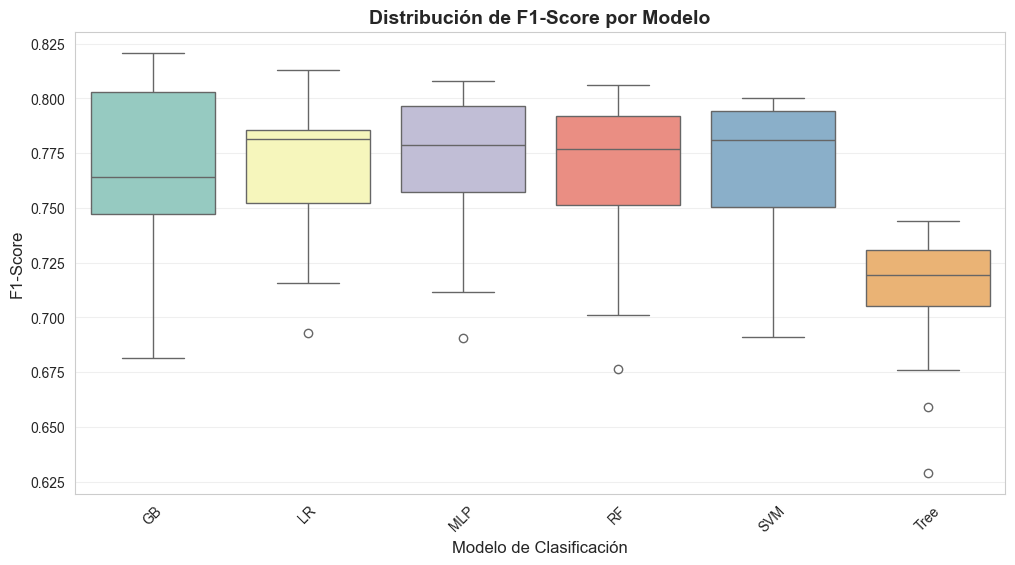

In [40]:
# Boxplot de F1 por modelo

plt.figure(figsize=(12, 6))
sns.boxplot(data=df_global, x='Modelo', y='f1', palette='Set3')
plt.title('Distribución de F1-Score por Modelo', fontweight='bold', fontsize=14)
plt.xlabel('Modelo de Clasificación', fontsize=12)
plt.ylabel('F1-Score', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
guardar_grafica("boxplot_f1_por_modelo.png")
plt.show()

### 3.4 Heatmap selector × modelo (todos k)

In [42]:
# RENDIMIENTO PROMEDIO POR SELECTOR Y MODELO

pivot_inter = df_global.pivot_table(index="FS", columns="Modelo", values="f1", aggfunc="mean").round(4)

print("RENDIMIENTO PROMEDIO de F1 POR SELECTOR Y MODELO:")
display(pivot_inter.style.background_gradient(cmap="Blues"))

RENDIMIENTO PROMEDIO de F1 POR SELECTOR Y MODELO:


Modelo,GB,LR,MLP,RF,SVM,Tree
FS,,,,,,
ANOVA,0.765200,0.767000,0.764900,0.748100,0.754500,0.704400
E2EFS,0.755700,0.779000,0.766300,0.761400,0.776300,0.708700
MI,0.747800,0.742200,0.757700,0.772800,0.754300,0.697000
NO FS,0.820900,0.781600,0.796400,0.806300,0.794200,0.730700
RFE-SVM,0.786100,0.781600,0.788700,0.778600,0.788200,0.730000
ReliefF,0.736900,0.753000,0.751800,0.745100,0.742000,0.693700
mRMR,0.769900,0.794100,0.776400,0.764200,0.782300,0.725700


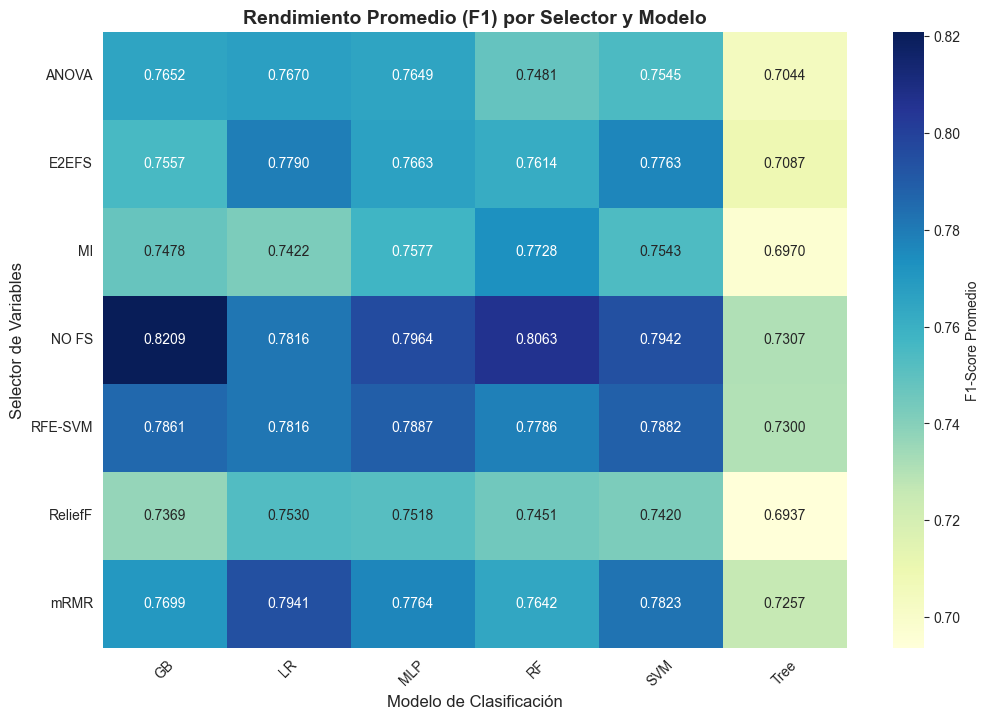

In [43]:
# Heatmap de F1 por selector y modelo

plt.figure(figsize=(12, 8))
sns.heatmap(pivot_inter, annot=True, fmt=".4f", cmap="YlGnBu", cbar_kws={'label': 'F1-Score Promedio'})
plt.title('Rendimiento Promedio (F1) por Selector y Modelo', fontsize=14, fontweight='bold')
plt.xlabel('Modelo de Clasificación', fontsize=12)
plt.ylabel('Selector de Variables', fontsize=12)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
guardar_grafica("heatmap_f1_selector_modelo.png")
plt.show()

In [21]:
pivot_inter = (
    df_global[df_global['k'] == 20]
    .pivot_table(index="FS", columns="Modelo", values="f1", aggfunc="mean")
    .round(4)
)

print("RENDIMIENTO PROMEDIO de F1 POR SELECTOR Y MODELO (k=20):")
display(pivot_inter.style.background_gradient(cmap="Blues"))

RENDIMIENTO PROMEDIO de F1 POR SELECTOR Y MODELO (k=20):


Modelo,GB,LR,MLP,RF,SVM,Tree
FS,,,,,,
ANOVA,0.764300,0.783300,0.774700,0.754000,0.743800,0.719400
E2EFS,0.758100,0.756900,0.767300,0.773100,0.760000,0.709700
MI,0.759400,0.773700,0.783500,0.777000,0.796900,0.676100
NO FS,0.820900,0.781600,0.796400,0.806300,0.794200,0.730700
RFE-SVM,0.792500,0.782900,0.801600,0.782800,0.800200,0.731600
ReliefF,0.740000,0.745400,0.735900,0.749600,0.725400,0.711800
mRMR,0.807700,0.803100,0.806500,0.768400,0.796500,0.731300


### 3.5. Jaccard entre selectores

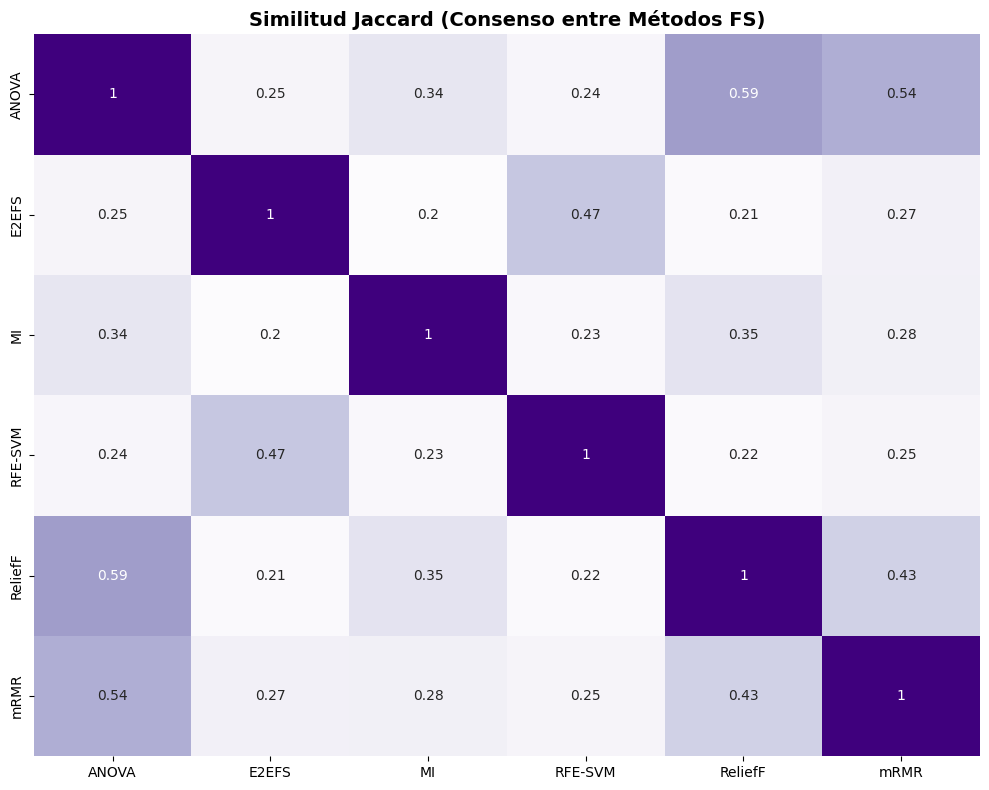

In [22]:
# Similitud Jaccard entre Selectores

fig, ax = plt.subplots(figsize=(10, 8))

# Filtramos NO FS
all_selectors = sorted([s for s in df_global['FS'].unique() if s != 'NO FS'])

n_sel = len(all_selectors)
mat_acumulada = np.zeros((n_sel, n_sel))

for k_val in resultados_sin_nulos_pais_k.keys():
    feat_sel = resultados_sin_nulos_pais_k[k_val]["features"]

    sets = {s: set(np.concatenate(feat_sel[s])) for s in all_selectors if s in feat_sel}

    for i, s1 in enumerate(all_selectors):
        for j, s2 in enumerate(all_selectors):

            if s1 in sets and s2 in sets:
                inter = len(sets[s1] & sets[s2])
                union = len(sets[s1] | sets[s2])

                mat_acumulada[i, j] += (inter / union if union > 0 else 0)

df_jac_mean = pd.DataFrame(mat_acumulada / len(resultados_sin_nulos_pais_k), index=all_selectors, columns=all_selectors)

sns.heatmap(df_jac_mean, annot=True, cmap="Purples", cbar=False, ax=ax)
ax.set_title("Similitud Jaccard (Consenso entre Métodos FS)", fontsize=14, fontweight='bold')
plt.tight_layout()
guardar_grafica("jaccard_selectores.png")
plt.show()

### 3.6. Mapa de selectores ganadores

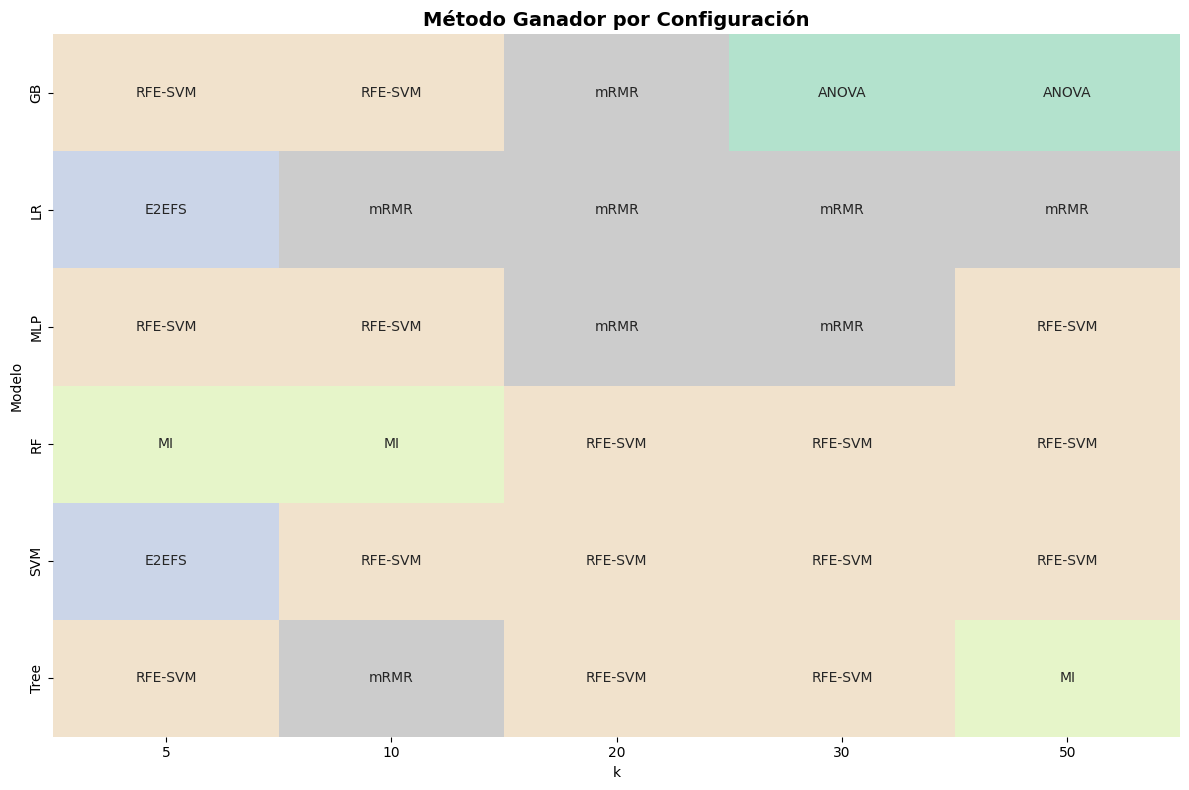

In [23]:
# Mejor Selector por Modelo y K

fig, ax = plt.subplots(figsize=(12, 8))

# Eliminamos NO FS también aquí
df_filtrado = df_global[df_global['FS'] != 'NO FS']

# Mejor selector por combinación k-modelo
idx = df_filtrado.groupby(['k', 'Modelo'])['f1'].idxmax()

df_gan = (df_filtrado.loc[idx, ['k', 'Modelo', 'FS']].pivot(index='Modelo', columns='k', values='FS'))

# Mapeo de categorías a enteros
cats = sorted(df_gan.stack().unique())
mapa_cat = {c: i for i, c in enumerate(cats)}

sns.heatmap(df_gan.replace(mapa_cat).infer_objects(copy=False), cmap="Pastel2", annot=df_gan, fmt="", cbar=False, ax=ax)

ax.set_title("Método Ganador por Configuración", fontsize=14, fontweight='bold')
plt.tight_layout()
guardar_grafica("metodos_ganadores.png")
plt.show()

### 3.7 Ganancia marginal entre k 

In [24]:
# GANANCIA MARGINAL ENTRE VALORES DE K
stats_k = (
    df_global[df_global['FS'] != 'NO FS']
    .groupby('k')['f1']
    .agg(['max', 'mean'])
    .rename(columns={'max': 'F1 Máx', 'mean': 'F1 Medio'})
)

stats_k['Δ F1 Máx (%)']   = (stats_k['F1 Máx'].diff() * 100).round(2)
stats_k['Δ F1 Medio (%)'] = (stats_k['F1 Medio'].diff() * 100).round(2)
f1_baseline = df_global[df_global['FS'] == 'NO FS']['f1'].mean()
stats_k['Supera baseline'] = stats_k['F1 Máx'].apply(lambda x: '✓' if x > f1_baseline else '✗')
print(f"Baseline NO-FS: {f1_baseline:.4f}")
display(stats_k.style.background_gradient(subset=['F1 Máx', 'F1 Medio'], cmap='Greens'))

Baseline NO-FS: 0.7883


,F1 Máx,F1 Medio,Δ F1 Máx (%),Δ F1 Medio (%),Supera baseline
k,,,,,
5,0.778250,0.722134,nan,nan,✗
10,0.802306,0.748459,2.410000,2.630000,✓
20,0.807665,0.762349,0.540000,1.390000,✓
30,0.817543,0.773094,0.990000,1.070000,✓
50,0.817504,0.773321,-0.000000,0.020000,✓


### 3.8 Rendimiento global + dispersión

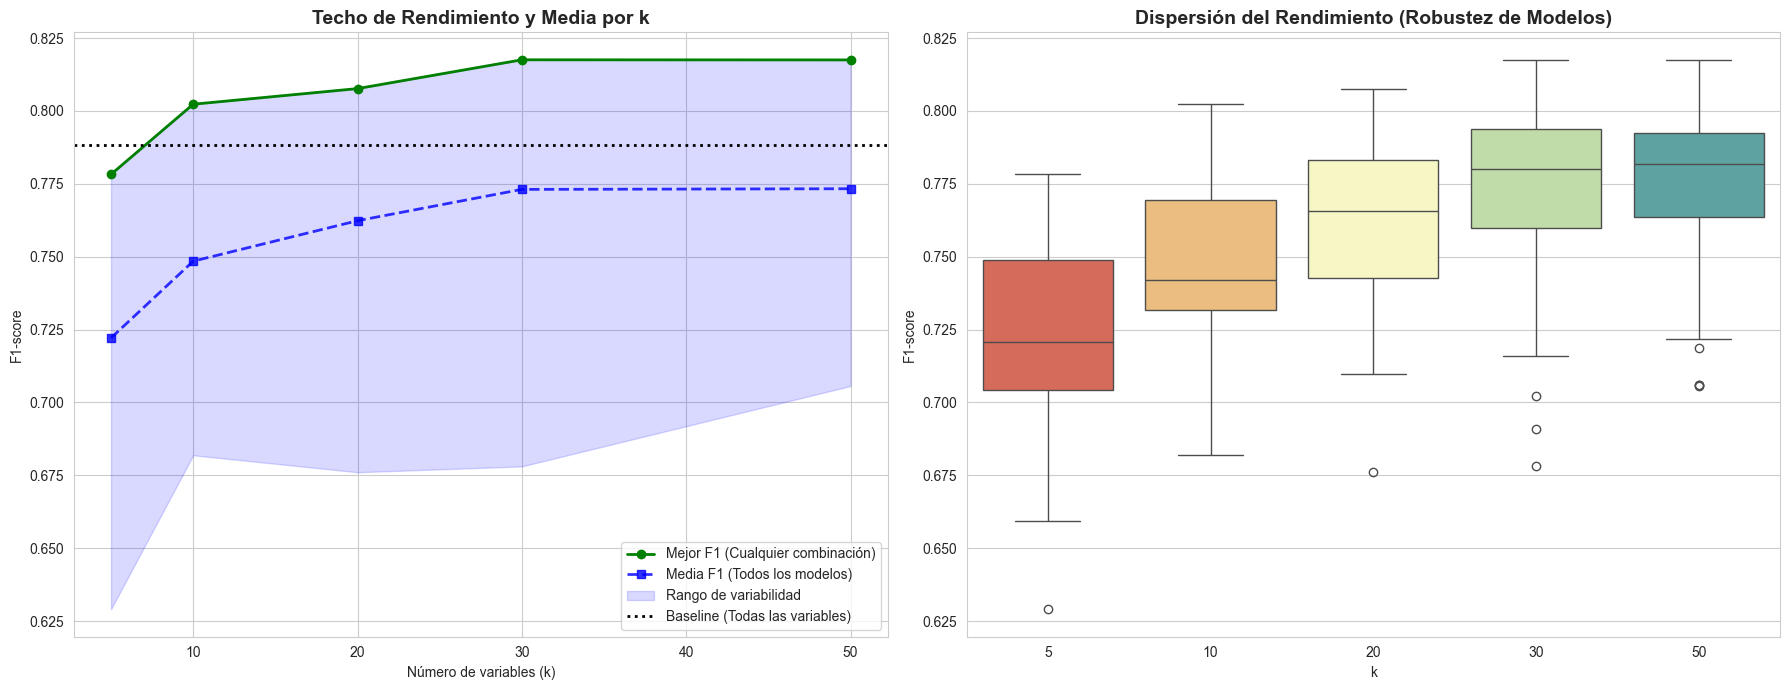

In [25]:
# RENDIMIENTO GLOBAL Y DISPERSIÓN (F1-SCORE)

sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# A. Rendimiento Global (Max/Mean/Min)
ax = axes[0]
stats = df_global[df_global['FS'] != 'NO FS'].groupby("k")["f1"].agg(['max', 'mean', 'min'])
ax.plot(stats["max"], 'o-', lw=2, color='green', label='Mejor F1 (Cualquier combinación)')
ax.plot(stats["mean"], 's--', lw=2, color='blue', alpha=0.8, label='Media F1 (Todos los modelos)')
ax.fill_between(stats.index, stats["min"], stats["max"], alpha=0.15, color='blue', label='Rango de variabilidad')

# Añadimos línea de NO FS como referencia visual
val_no_fs = df_global[df_global['FS'] == 'NO FS']['f1'].mean()
ax.axhline(y=val_no_fs, color='black', linestyle=':', lw=2, label='Baseline (Todas las variables)')

ax.set_title("Techo de Rendimiento y Media por k", fontsize=14, fontweight='bold')
ax.set_xlabel("Número de variables (k)"), ax.set_ylabel("F1-score"), ax.legend(loc='lower right')

# B. Boxplot de Robustez
ax = axes[1]
sns.boxplot(data=df_global[df_global['FS'] != 'NO FS'], x='k', y='f1', palette="Spectral", ax=ax)
ax.set_title("Dispersión del Rendimiento (Robustez de Modelos)", fontsize=14, fontweight='bold')
ax.set_ylabel("F1-score")

plt.tight_layout()
guardar_grafica("rendimiento_global_f1_por_k.png")
plt.show()

### 3.9. Mejor Combinación por K

In [26]:
# MEJOR COMBINACIÓN POR K

mejores_por_k = (
    df_global[df_global['FS'] != 'NO FS']
    .groupby('k')
    .apply(lambda x: x.loc[x['f1'].idxmax()])
    .reset_index(drop=True)
)[['k', 'FS', 'Modelo', 'f1', 'accuracy', 'precision', 'recall', 'roc_auc']]

mejores_por_k.columns = ['k', 'Selector', 'Modelo', 'F1', 'Accuracy', 'Precisión', 'Recall', 'AUC']
print("MEJOR COMBINACIÓN SELECTOR+MODELO POR K (configuración definitiva):")
display(mejores_por_k.style.background_gradient(subset=['F1'], cmap='Greens'))

MEJOR COMBINACIÓN SELECTOR+MODELO POR K (configuración definitiva):


,k,Selector,Modelo,F1,Accuracy,Precisión,Recall,AUC
0,5,E2EFS,LR,0.778250,0.779907,0.787927,0.779907,0.845911
1,10,mRMR,LR,0.802306,0.803717,0.815214,0.803717,0.883482
2,20,mRMR,GB,0.807665,0.808595,0.813128,0.808595,0.853934
3,30,ANOVA,GB,0.817543,0.818118,0.824171,0.818118,0.862286
4,50,ANOVA,GB,0.817504,0.818118,0.823492,0.818118,0.873340


## **4. Análisis de Selección de Características por Selector y K**

### 4.1. Estabilidad de Selección por Selector en función de K

In [27]:
# ESTABILIDAD POR SELECTOR EN FUNCIÓN DE K

stab_list = []

for k, res in resultados_sin_nulos_pais_k.items():
    # Obtenemos la estabilidad para cada k
    df = res["stability"][["feature_name", "selector", "pct_selected"]].copy()
    df["k"] = k
    stab_list.append(df)

df_stab_all = pd.concat(stab_list, ignore_index=True).round(2)

pivot_stab = df_stab_all.pivot_table(index="selector", columns="k", values="pct_selected", aggfunc="mean")
display(pivot_stab.style.background_gradient(cmap="Greens"))

k,5,10,20,30,50
selector,,,,,
ANOVA,50.000000,52.631579,57.142857,62.500000,75.757576
E2EFS,41.666667,38.461538,37.037037,41.666667,45.045045
MI,31.250000,31.250000,37.037037,41.095890,48.543689
RFE-SVM,38.461538,41.666667,37.735849,38.461538,39.682540
ReliefF,45.454545,50.000000,55.555556,65.217391,75.757576
mRMR,38.461538,43.478261,55.555556,57.692308,65.789474


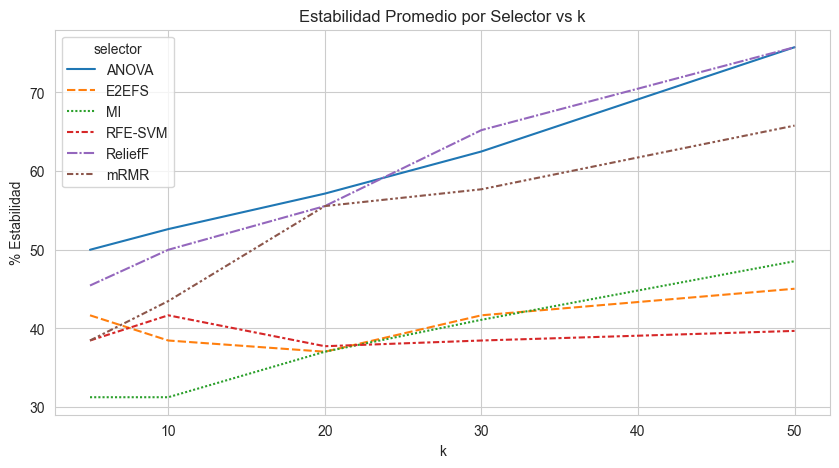

In [28]:
plt.figure(figsize=(10,5))
sns.lineplot(data=pivot_stab.T)
plt.title("Estabilidad Promedio por Selector vs k")
plt.xlabel("k")
plt.ylabel("% Estabilidad")
plt.grid(True)
guardar_grafica("estabilidad_selector_vs_k.png")
plt.show()

### 4.2. Frecuencia de Características Seleccionadas por Selector agregando K

In [29]:
# Analisis de las características más repetidas por método de selección

print("ANÁLISIS DE FRECUENCIA DE CARACTERÍSTICAS (AGREGADO SOBRE TODOS LOS K):")
top_n = 10
html_tables = []

# 1. Agrupar por selector y característica, calculando la media de estabilidad
df_feature_overall_stats = df_stab_all.groupby(['selector', 'feature_name']).agg(Frecuencia_Media=('pct_selected', 'mean')).reset_index()

# Estilos CSS
container_style = "overflow-x: auto; white-space: nowrap; margin-bottom: 20px; font-size: 12px;"

# 2. Iterar y generar el HTML de cada tabla
for selector_name in df_feature_overall_stats['selector'].unique():
    df_top_features = df_feature_overall_stats[df_feature_overall_stats['selector'] == selector_name].sort_values('Frecuencia_Media', ascending=False).head(top_n)
    
    df_display = df_top_features[['feature_name', 'Frecuencia_Media']].rename(columns={'feature_name': 'Característica', 'Frecuencia_Media': 'Estabilidad Media (%)'})
    
    # Usar Pandas Styler para formato de dos decimales
    styled_df = df_display.style.format({'Estabilidad Media (%)': "{:.2f}" }).set_caption(f"{selector_name} (Top {top_n})")

    # Generar HTML para mejor visualización
    html = styled_df.to_html()
    table_wrapper = f"<div style='display: inline-block; vertical-align: top; margin-right: 5px; width: 350px; white-space: normal;'>{html}</div>"
    html_tables.append(table_wrapper)

# 3. Unir y mostrar todas las tablas en una fila con scroll horizontal
display(HTML(f"<div style='{container_style}'>{''.join(html_tables)}</div>"))

ANÁLISIS DE FRECUENCIA DE CARACTERÍSTICAS (AGREGADO SOBRE TODOS LOS K):


,Característica,Estabilidad Media (%)
48,permanece_apartado,100.00
13,Utiliza_reloj,100.00
33,frecuencia_ofensiva,100.00
25,cuenta_historia,100.00
2,Frecuencia_retraimiento,95.00
39,intercambia_objetos,92.00
63,trabaja_ritmo_regular,88.00
32,fecuencia_estereotipias,86.67
58,responde_negativamente_a_ordenes,85.00
52,recados_bien,80.00


### 4.3. Frecuencia de Características Seleccionadas por Selector para cada k

In [30]:
# Analisis de las características más repetidas por método de selección

print("ANÁLISIS DE FRECUENCIA DE CARACTERÍSTICAS POR VALOR DE K:")
top_n = 10
unique_k = sorted(df_stab_all['k'].unique())

# Estilos CSS para el contenedor principal
container_style = "overflow-x: auto; white-space: nowrap; margin-bottom: 20px; font-size: 12px; border: 1px solid #ddd; padding: 10px;"

for k_value in unique_k:
    print(f"\n K = {k_value}")
    
    # Filtrar df_stab_all para el valor actual de k
    df_k = df_stab_all[df_stab_all['k'] == k_value].copy()
    
    # 1. Agrupar por selector y característica, calculando la estabilidad media (solo un valor de k, pero la estructura es consistente)
    df_feature_stats_k = df_k.groupby(['selector', 'feature_name']).agg(
        Estabilidad_Media=('pct_selected', 'mean')
    ).reset_index()
    
    html_tables_k = []
    
    # 2. Iterar y generar el HTML de cada tabla para este K
    for selector_name in df_feature_stats_k['selector'].unique():
        df_top_features = df_feature_stats_k[
            df_feature_stats_k['selector'] == selector_name
        ].sort_values('Estabilidad_Media', ascending=False).head(top_n)
        
        df_display = df_top_features[['feature_name', 'Estabilidad_Media']].rename(
            columns={'feature_name': 'Característica', 'Estabilidad_Media': 'Estabilidad Media (%)'}
        )
        
        # Usar Pandas Styler para formato de dos decimales
        styled_df = df_display.style.format({
            'Estabilidad Media (%)': "{:.2f}" 
        }).set_caption(f"{selector_name} (Top {top_n})")

        # Generar HTML con ancho fijo y margen reducido
        html = styled_df.to_html()
        table_wrapper = f"<div style='display: inline-block; vertical-align: top; margin-right: 5px; width: 350px; white-space: normal;'>{html}</div>"
        html_tables_k.append(table_wrapper)

    # 3. Mostrar todas las tablas para el valor actual de K en un contenedor con scroll
    display(HTML(f"<div style='{container_style}'>{''.join(html_tables_k)}</div>"))

ANÁLISIS DE FRECUENCIA DE CARACTERÍSTICAS POR VALOR DE K:

 K = 5


,Característica,Estabilidad Media (%)
7,permanece_apartado,100.00
2,cuenta_historia,100.00
9,trabaja_ritmo_regular,60.00
4,hacer_cosas_repetidamente,60.00
5,intercambia_objetos,60.00
3,evita_contacto_ocular,40.00
1,Gravedad_retraimiento,20.00
0,Gravedad_no_colaboradora,20.00
6,mira_lejos_cuando_se_lo_mira,20.00
8,repite_sonidos_ininteligibles,20.00



 K = 10


,Característica,Estabilidad Media (%)
15,permanece_apartado,100.00
11,intercambia_objetos,100.00
8,cuenta_historia,100.00
18,trabaja_ritmo_regular,80.00
3,Gravedad_retraimiento,80.00
1,Frecuencia_retraimiento,80.00
16,repite_sonidos_ininteligibles,60.00
9,evita_contacto_ocular,60.00
10,hacer_cosas_repetidamente,60.00
14,ofrece_ayuda,40.00



 K = 20


,Característica,Estabilidad Media (%)
1,Frecuencia_retraimiento,100.00
2,Gravedad_no_colaboradora,100.00
3,Gravedad_retraimiento,100.00
28,repite_sonidos_ininteligibles,100.00
14,cuenta_historia,100.00
26,permanece_apartado,100.00
32,trabaja_ritmo_regular,100.00
22,intercambia_objetos,100.00
29,responde_negativamente_a_ordenes,100.00
19,fecuencia_estereotipias,80.00



 K = 30


,Característica,Estabilidad Media (%)
3,Gravedad_no_colaboradora,100.00
2,Frecuencia_retraimiento,100.00
4,Gravedad_retraimiento,100.00
11,Utiliza_reloj,100.00
45,trabaja_ritmo_regular,100.00
35,permanece_apartado,100.00
30,intercambia_objetos,100.00
21,cuenta_historia,100.00
38,repite_sonidos_ininteligibles,100.00
33,no_inicia_conversaciones,100.00



 K = 50


,Característica,Estabilidad Media (%)
64,usa_palabras_correctamente,100.00
56,repite_sonidos_ininteligibles,100.00
9,Retraimiento_atencion,100.00
11,Ubicación_residencial_recomendacion,100.00
13,Utiliza_reloj,100.00
14,administra_dinero,100.00
16,barrio_curza_calles,100.00
43,mira_lejos_cuando_se_lo_mira,100.00
45,no_inicia_conversaciones,100.00
47,ofrece_ayuda,100.00


### 4.4. Características Consistentes entre Selectores por K

In [31]:
# CARACTERÍSTICAS CONSISTENTES ENTRE SELECTORES POR K

html_output = ""

for k, res in resultados_sin_nulos_pais_k.items():
    df = res["stability"]
    
    # filtrar features estables
    df_f = (
        df[df['pct_selected'] >= 60]
        .groupby("feature_name")
        .agg(
            Num_selectores=('selector','count'),
            Estabilidad=('pct_selected','mean'))
        .round(2)
        .sort_values(['Num_selectores','Estabilidad'], ascending=False))
    
    # Generamos el HTML del DataFrame con el gradiente aplicado
    # Usamos .to_html() sobre el objeto Styler
    table_html = df_f.style.background_gradient(cmap="Greens").to_html()
    
    # Añadimos al string global un bloque HTML que contiene el título y la tabla
    # inline-block permite que se coloquen uno al lado del otro
    html_output += f"""
    <div style="display: inline-block; vertical-align: top; margin-right: 40px; margin-bottom: 20px;">
        <h4 style="text-align: center; border-bottom: 2px solid #2e7d32; padding-bottom: 5px;">K = {k}</h4>
        {table_html}
    </div>
    """

# Mostramos todo el bloque HTML acumulado
display_html(html_output, raw=True)

,Num_selectores,Estabilidad
feature_name,,
permanece_apartado,4,95.000000
cuenta_historia,4,85.000000
Medicamentos,3,80.000000
intercambia_objetos,3,73.330000
trabaja_ritmo_regular,2,60.000000
comunicq,1,100.000000
Edad,1,60.000000
esperar_turno,1,60.000000
evita_contacto_ocular,1,60.000000


### 4.5. Características más estables

In [32]:
# CARACTERÍSTICAS MÁS ESTABLES

df_feat_global = (df_stab_all.groupby("feature_name")["pct_selected"].mean().sort_values(ascending=False)).round(4)

print("CARACTERÍSTICAS MÁS ESTABLES EN GENERAL:")
display(df_feat_global.head(20).to_frame().style.background_gradient(cmap="Greens"))

CARACTERÍSTICAS MÁS ESTABLES EN GENERAL:


,pct_selected
feature_name,
permanece_apartado,90.000000
cuenta_historia,84.666700
socialq,84.000000
intercambia_objetos,83.448300
Frecuencia_retraimiento,81.333300
Medicamentos,77.391300
responde_negativamente_a_ordenes,77.142900
repite_sonidos_ininteligibles,75.000000
esperar_turno,73.846200


**NOTA**: No tener en cuenta esta celda, ya que solo mide la media de la estabilidad de cada característica, por lo que una variable podría tener una media alta en un solo selector pero no aparecer en ningún otro selector.

### **4.6. Análisis Definitivo de Características Consistentes**

#### 4.6.1 Persistencia de Características (invariancia a K)

In [33]:
# CÁLCULO DE PERSISTENCIA
persistence_list = []
unique_ks = sorted(df_stab_all['k'].unique())
num_ks = len(unique_ks)

for sel in df_stab_all['selector'].unique():
    counts = df_stab_all[df_stab_all['selector'] == sel].groupby('feature_name')['k'].nunique()
    persistent_features = counts[counts == num_ks].index.tolist()
    for f in persistent_features:
        persistence_list.append({'selector': sel, 'feature_name': f, 'Persistente': True})

df_persistence = pd.DataFrame(persistence_list)

print("VARIABLES CON PERSISTENCIA TOTAL (Invariantes ante el valor de k):")
display(df_persistence.groupby('feature_name')['selector'].apply(list))

VARIABLES CON PERSISTENCIA TOTAL (Invariantes ante el valor de k):


feature_name
Audición                                                              [RFE-SVM]
Edad                                                                     [mRMR]
Estado_legal                                                             [mRMR]
Gravedad_no_colaboradora                                                [ANOVA]
Gravedad_retraimiento                                                   [ANOVA]
Localiza_informacion                                                  [RFE-SVM]
Medicamentos                                             [E2EFS, RFE-SVM, mRMR]
Retraimiento_atencion                                                 [ReliefF]
Salud                                                                      [MI]
barrio_curza_calles                                             [ReliefF, mRMR]
carcajea_inapropiadamente                                             [ReliefF]
comportamineto_autolesivo                                                [mRMR]
comunic                    

#### 4.6.2 Cálculo y Ranking de Consenso Global (k=20)

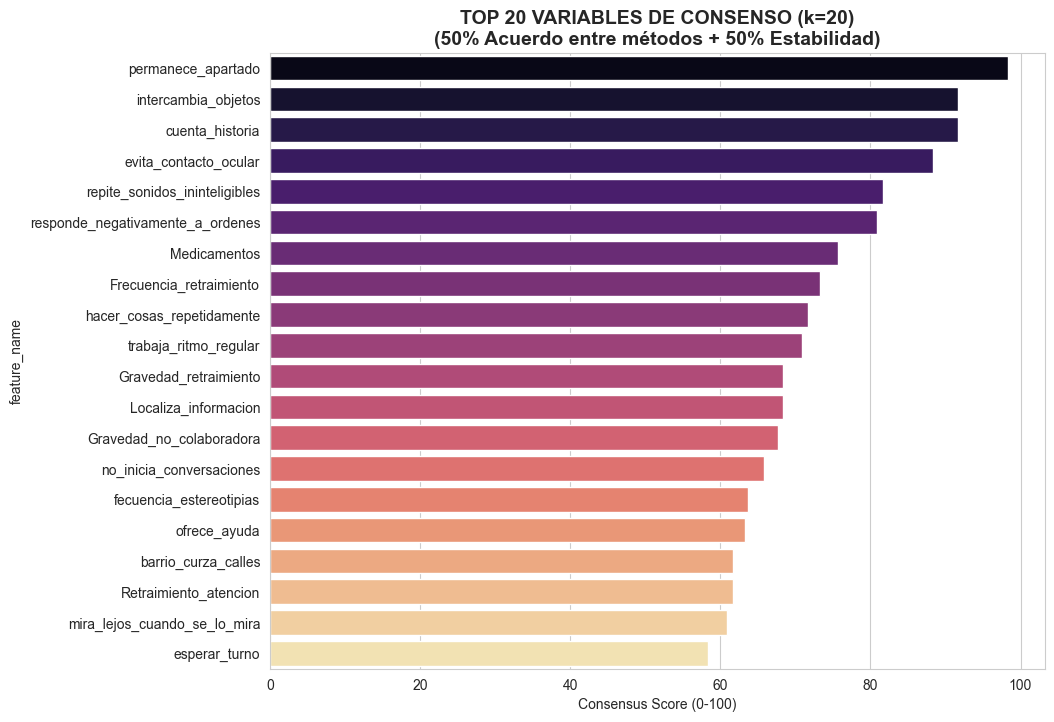

In [34]:
# CÁLCULO Y RANKING DE CONSENSO GLOBAL (k=20)

# Parámetros y Carga
k_optimo = 20 
df_sav, meta = pyreadstat.read_sav("TEA_1.sav")
X_full = df_sav.drop(columns=['Diag_primario'])
y_full = df_sav['Diag_primario']

# Cálculo del Score de Consenso
df_cons_global = df_stab_all[df_stab_all['k'] == k_optimo].groupby('feature_name').agg({
    'selector': 'nunique',
    'pct_selected': 'mean'
}).rename(columns={'selector': 'Acuerdo_Selectores', 'pct_selected': 'Estabilidad_Media'})

# Normalización: 50% Acuerdo (Nº métodos) + 50% Estabilidad (Frecuencia en folds)
df_cons_global['Consensus_Score'] = (
    (df_cons_global['Acuerdo_Selectores'] / df_stab_all['selector'].nunique()) * 50 + 
    (df_cons_global['Estabilidad_Media'] / 100) * 50
)

# Visualización del Top 20
top_consensus = df_cons_global.sort_values('Consensus_Score', ascending=False).head(20)

plt.figure(figsize=(10, 8))
sns.barplot(x=top_consensus['Consensus_Score'], y=top_consensus.index, hue=top_consensus.index, palette="magma", legend=False)
plt.title(f"TOP 20 VARIABLES DE CONSENSO (k={k_optimo})\n(50% Acuerdo entre métodos + 50% Estabilidad)", fontsize=14, fontweight='bold')
plt.xlabel("Consensus Score (0-100)")
guardar_grafica("ranking_consenso.png")
plt.show()

#### 4.6.3 Análisis de Separabilidad con las 5, 10 y 20 Características más Consistentes

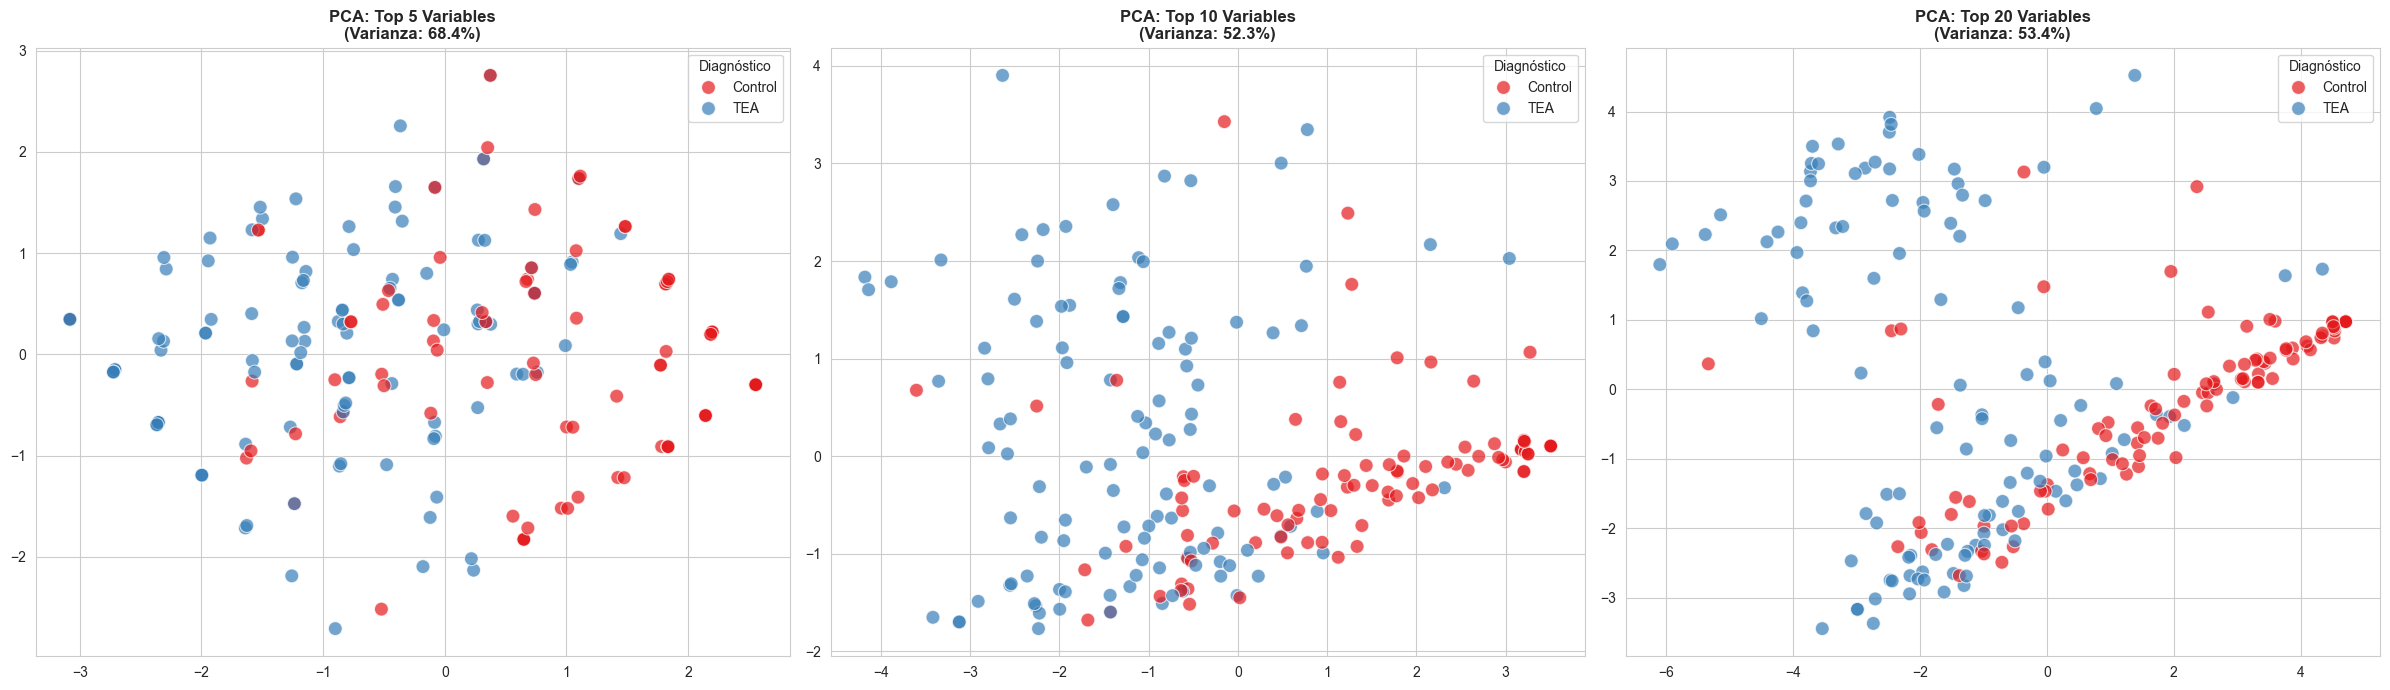

In [35]:
# MAPEAMOS LOS NOMBRES PARA LA LEYENDA
# Asumimos 1.0 = Control y 2.0 = TEA según la codificación habitual

y_labels = np.where(y_full == 1.0, 'Control', 'TEA')
ks_to_test = [5, 10, 20]

# ANÁLISIS DE SEPARABILIDAD: PCA (k=5, 10, 20)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for i, k_val in enumerate(ks_to_test):
    # Selección y preprocesamiento
    top_feats = top_consensus.head(k_val).index.tolist()
    X_scaled = StandardScaler().fit_transform(KNNImputer(n_neighbors=5).fit_transform(X_full[top_feats]))
    
    # PCA
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_scaled)
    var_exp = pca.explained_variance_ratio_.sum() * 100
    
    # Gráfico
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_labels, 
                    palette="Set1", s=100, alpha=0.7, ax=axes[i])
    axes[i].set_title(f"PCA: Top {k_val} Variables\n(Varianza: {var_exp:.1f}%)", fontweight='bold')
    axes[i].legend(title="Diagnóstico")

plt.tight_layout()
guardar_grafica("pca_top_variables.png")
plt.show()

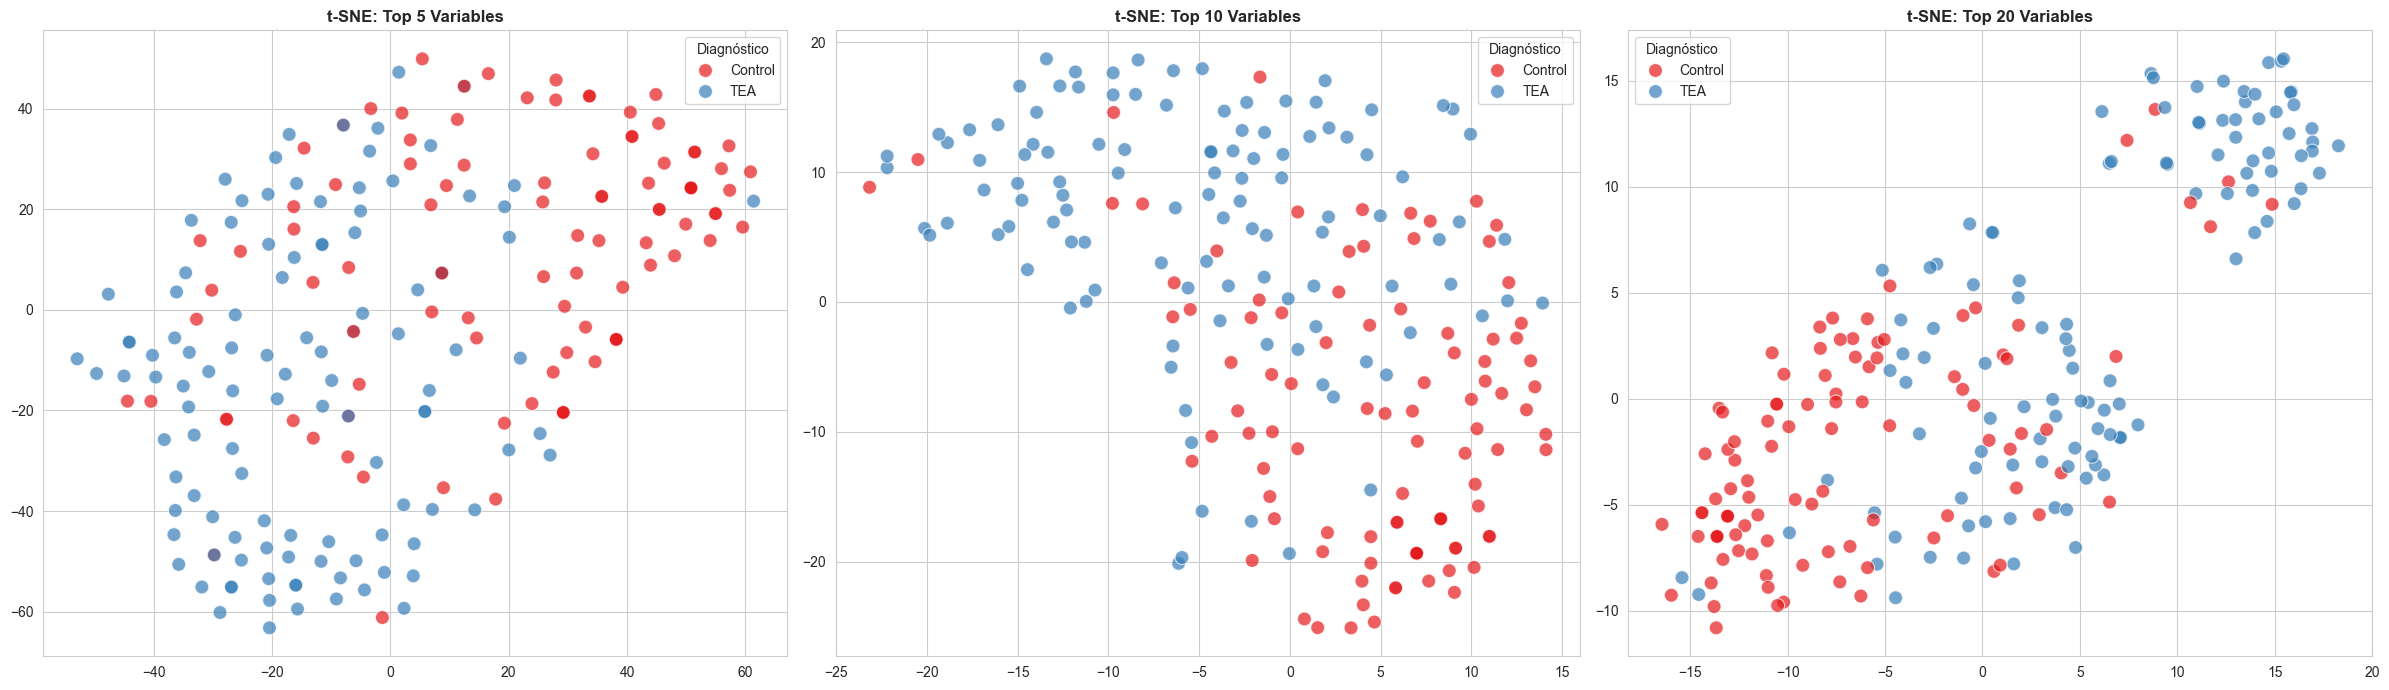

In [36]:
# ANÁLISIS DE SEPARABILIDAD: t-SNE (k=5, 10, 20)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for i, k_val in enumerate(ks_to_test):
    # Selección y preprocesamiento
    top_feats = top_consensus.head(k_val).index.tolist()
    X_scaled = StandardScaler().fit_transform(KNNImputer(n_neighbors=5).fit_transform(X_full[top_feats]))
    
    # t-SNE (Parámetros estándar: perplexity=30)
    tsne = TSNE(n_components=2, perplexity=30, random_state=42, init='pca', learning_rate='auto')
    X_tsne = tsne.fit_transform(X_scaled)
    
    # Gráfico
    sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_labels, 
                    palette="Set1", s=100, alpha=0.7, ax=axes[i])
    axes[i].set_title(f"t-SNE: Top {k_val} Variables", fontweight='bold')
    axes[i].legend(title="Diagnóstico")

plt.tight_layout()
guardar_grafica("tsne_top_variables.png")
plt.show()

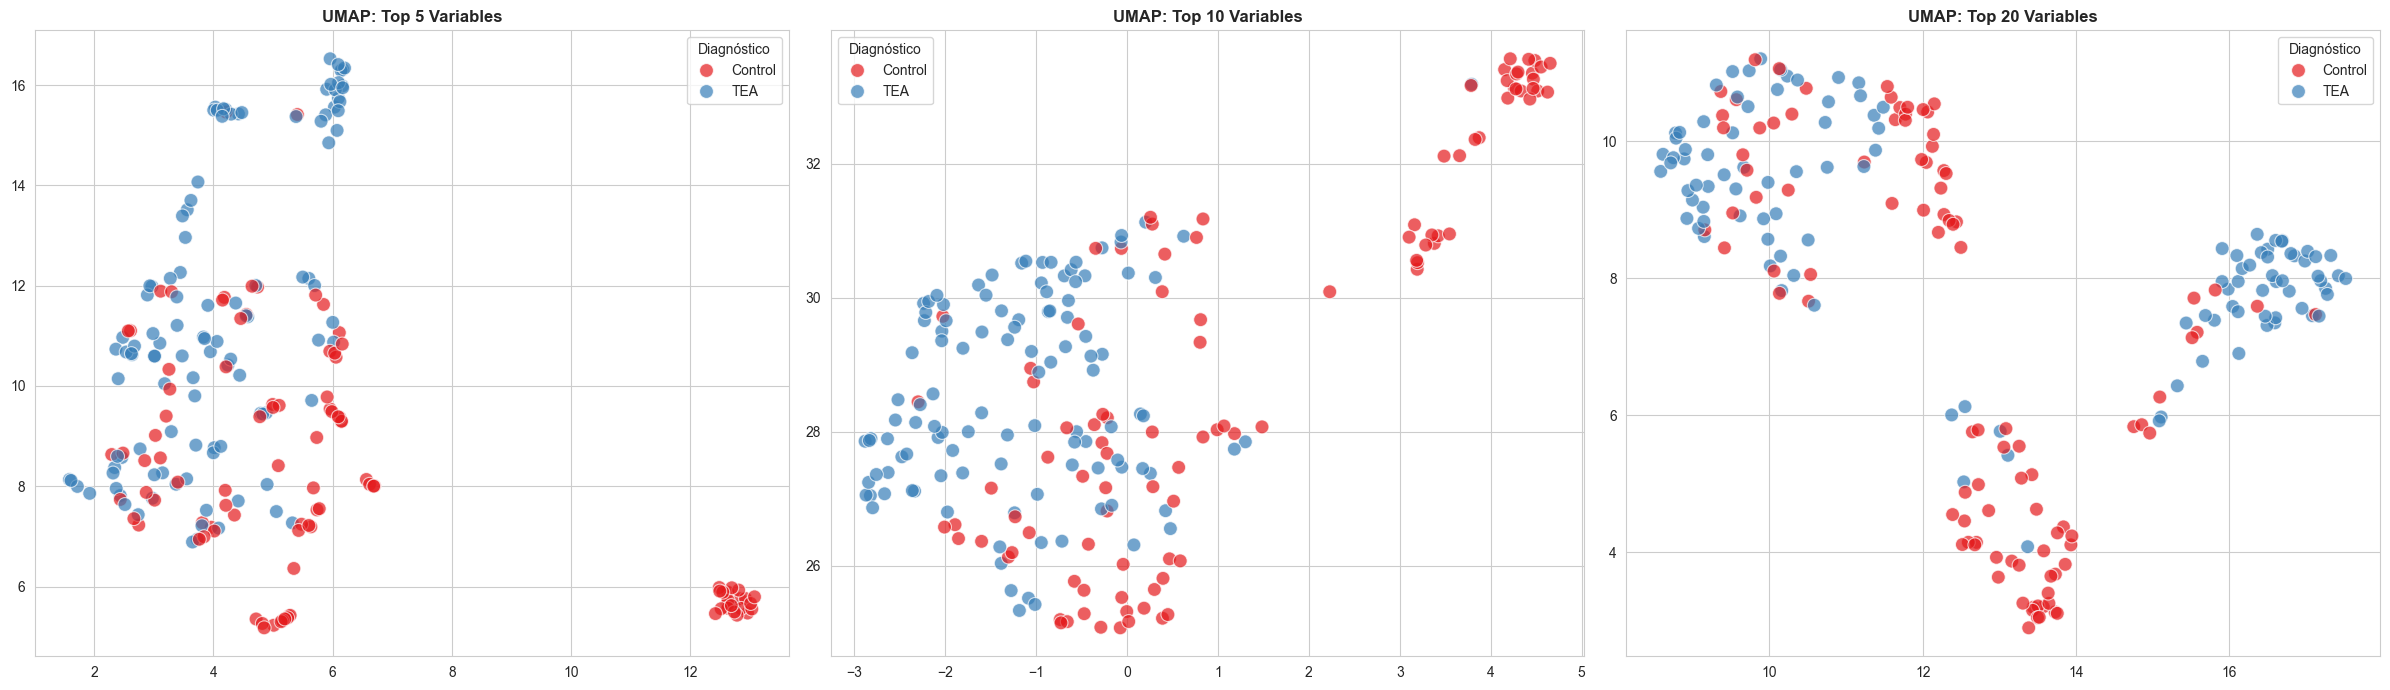

: 

In [ ]:
# ANÁLISIS DE SEPARABILIDAD: UMAP (k=5, 10, 20)

fig, axes = plt.subplots(1, 3, figsize=(24, 7))

for i, k_val in enumerate(ks_to_test):
    # Selección y preprocesamiento
    top_feats = top_consensus.head(k_val).index.tolist()
    X_scaled = StandardScaler().fit_transform(KNNImputer(n_neighbors=5).fit_transform(X_full[top_feats]))
    
    # UMAP (Parámetros estándar: n_neighbors=15)
    reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42)
    X_umap = reducer.fit_transform(X_scaled)
    
    # Gráfico
    sns.scatterplot(x=X_umap[:, 0], y=X_umap[:, 1], hue=y_labels, 
                    palette="Set1", s=100, alpha=0.7, ax=axes[i])
    axes[i].set_title(f"UMAP: Top {k_val} Variables", fontweight='bold')
    axes[i].legend(title="Diagnóstico")

plt.tight_layout()
guardar_grafica("umap_top_variables.png")
plt.show()

#### 4.6.4 Top 5 Variables más Relevantes por Selector

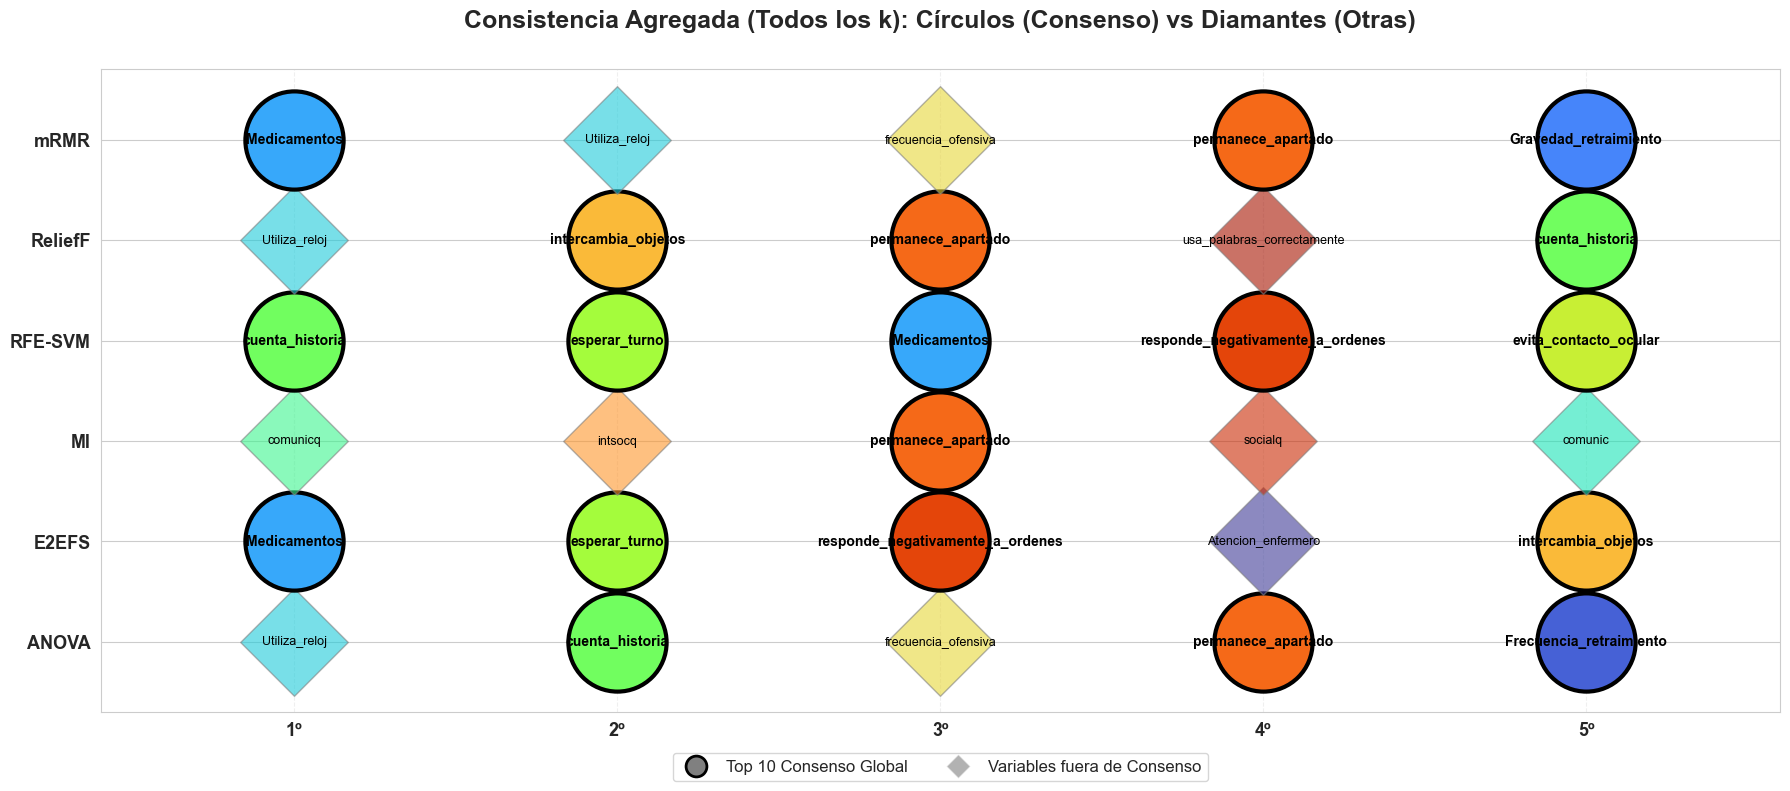

In [37]:
# CONSISTENCIA DE SELECTORES: AGREGADO DE TODOS LOS K

plt.figure(figsize=(18, 8))
ax = plt.gca()

# 1. Definimos el Top 20 del Consenso Global
top_global_names = top_consensus.index.tolist()[:20]

# 2. AGREGACIÓN: Calculamos la estabilidad media de cada variable por SELECTOR (media de todos los k)
df_agg_selector = df_stab_all.groupby(['selector', 'feature_name'])['pct_selected'].mean().reset_index()

selectors_list = sorted(df_agg_selector['selector'].unique())

# 3. Identificar TODAS las variables únicas en los Tops agregados para asignar colores
all_top_features = []
for sel in selectors_list:
    top5 = df_agg_selector[df_agg_selector['selector'] == sel].nlargest(5, 'pct_selected')['feature_name'].tolist()
    all_top_features.extend(top5)

unique_features = sorted(list(set(all_top_features)))
palette = sns.color_palette("turbo", len(unique_features))
color_map = dict(zip(unique_features, palette))

# 4. Dibujamos
for i, sel in enumerate(selectors_list):
    # Obtenemos las 5 mejores variables del selector considerando TODOS los k
    top5_agg = df_agg_selector[df_agg_selector['selector'] == sel].nlargest(5, 'pct_selected')['feature_name'].tolist()
    
    for rank, feat in enumerate(top5_agg):
        color = color_map[feat]
        
        if feat in top_global_names:
            # VARIABLE DE CONSENSO: Círculo, borde grueso, texto extra-negrita
            marker = 'o'
            size = 5000
            alpha = 1.0
            edge_color = 'black'
            linewidth = 3
            font_style = {'fontsize': 10, 'fontweight': 'extra bold'}
        else:
            # OTRA VARIABLE: Diamante, más pequeño, transparente
            marker = 'D'
            size = 3000
            alpha = 0.6
            edge_color = 'grey'
            linewidth = 1
            font_style = {'fontsize': 9, 'fontweight': 'normal'}
        
        # Dibujar figura
        ax.scatter(rank + 1, i, s=size, marker=marker, alpha=alpha, 
                   color=color, edgecolor=edge_color, linewidth=linewidth, zorder=2)
        
        # Texto dentro
        ax.text(rank + 1, i, feat, ha='center', va='center', color='black', **font_style)

# 5. Ajustes de formato y espaciado
ax.set_yticks(range(len(selectors_list)))
ax.set_yticklabels(selectors_list, fontsize=13, fontweight='bold')
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xticklabels(['1º', '2º', '3º', '4º', '5º'], fontsize=13, fontweight='bold')

# Ajustamos límites para que no haya aire innecesario
ax.set_xlim(0.4, 5.6) 
ax.set_ylim(-0.7, len(selectors_list) - 0.3)

ax.set_title("Consistencia Agregada (Todos los k): Círculos (Consenso) vs Diamantes (Otras)", 
             fontsize=18, fontweight='bold', pad=30)
ax.grid(True, axis='x', linestyle='--', alpha=0.3, zorder=1)

# Leyenda manual
legend_elements = [
    Line2D([0], [0], marker='o', color='w', label='Top 10 Consenso Global',
           markerfacecolor='grey', markersize=15, markeredgecolor='black', markeredgewidth=2),
    Line2D([0], [0], marker='D', color='w', label='Variables fuera de Consenso',
           markerfacecolor='grey', markersize=12, alpha=0.6)
]
ax.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, -0.05),
          ncol=2, fontsize=12, frameon=True)

plt.tight_layout()
guardar_grafica("top5_por_selector.png")
plt.show()

#### 4.6.5 Acuerdo entre Selectores en las Top 20 Variables más Consistentes para k=20

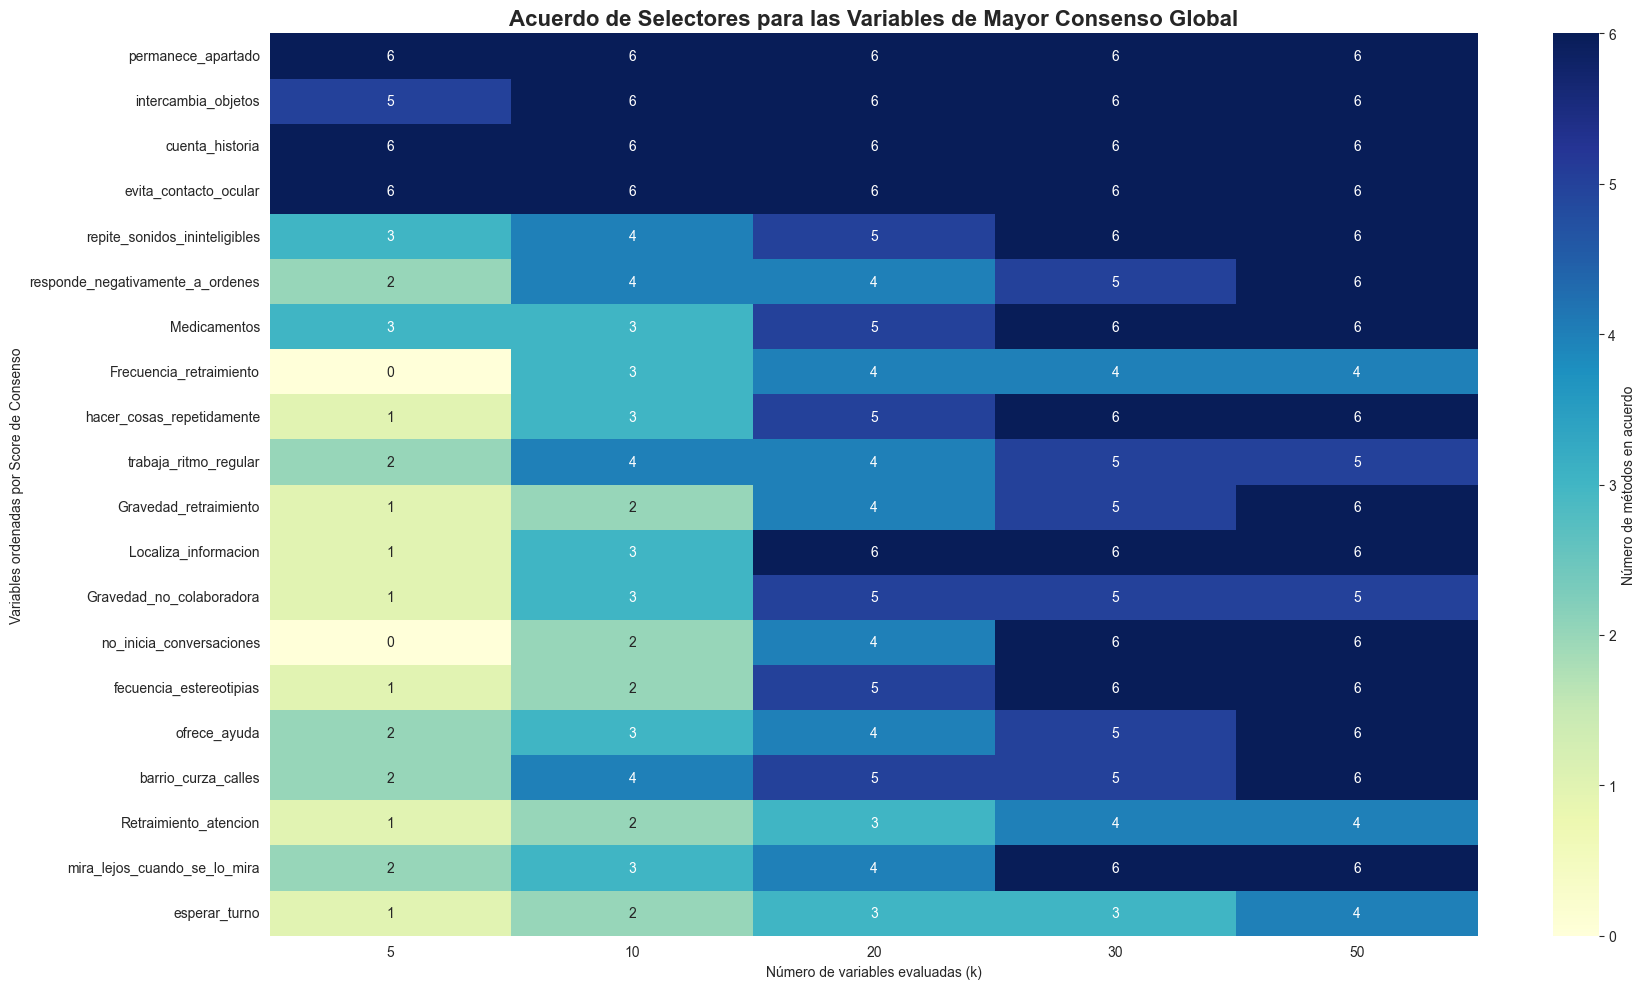

In [38]:
# ACUERDO ENTRE MÉTODOS PARA EL TOP 15 DE CONSENSO (Evolución por k)

plt.figure(figsize=(18, 10))
ax = plt.gca()

# 1. Usamos el índice de tu top_consensus (que ya son las 15 mejores por Score)
top_15_consensus_feats = top_consensus.index.tolist()

# 2. Filtramos df_stab_all para estas variables
df_consenso_map = df_stab_all[df_stab_all['feature_name'].isin(top_15_consensus_feats)]

# 3. Creamos la matriz: ¿Cuántos selectores coinciden en cada variable para cada k?
pivot_consenso_final = df_consenso_map[df_consenso_map['pct_selected'] > 0].pivot_table(
    index='feature_name', 
    columns='k', 
    values='selector', 
    aggfunc='count'
).fillna(0).loc[top_15_consensus_feats] # Reordenamos según el ranking de consenso

sns.heatmap(pivot_consenso_final, annot=True, cmap="YlGnBu", ax=ax, cbar_kws={'label': 'Número de métodos en acuerdo'})
ax.set_title("Acuerdo de Selectores para las Variables de Mayor Consenso Global", fontsize=16, fontweight='bold')
ax.set_xlabel("Número de variables evaluadas (k)")
ax.set_ylabel("Variables ordenadas por Score de Consenso")

plt.tight_layout()
guardar_grafica("acuerdo_selectores_top15.png")
plt.show()